# **Laboratorio 3**

## Integrantes:
- Laura Sanchez Bernal - 202411353
- Baruc Jeronimo Triana Bastidas - 202416093

# 1. Exploración y calidad de datos
En esta etapa se realiza una exploración inicial del conjunto de datos para identificar las características de las variables, los tipos de datos y posibles problemas de calidad. Esta revisión permitirá determinar qué procedimientos de preparación serán necesarios antes de entrenar los modelos de clasificación.

In [24]:
import pandas as pd
import matplotlib.pyplot as plt


In [25]:
datos = pd.read_excel('./Data/Lab3_Datos.xlsx')
datos.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [26]:
data = datos.copy()

In [27]:
data.shape

(12664, 26)

In [28]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12664 entries, 0 to 12663
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   destino                          12664 non-null  str  
 1   acompanante                      12664 non-null  str  
 2   clima                            12664 non-null  str  
 3   temperatura                      12664 non-null  int64
 4   hora                             12664 non-null  str  
 5   cupon                            12664 non-null  str  
 6   vigencia_cupon                   12664 non-null  str  
 7   genero                           12664 non-null  str  
 8   edad                             12664 non-null  str  
 9   estado_civil                     12664 non-null  str  
 10  tiene_hijos                      12664 non-null  str  
 11  educacion                        12664 non-null  str  
 12  ocupacion                        12664 non-null  str  
 1

### 1.1. Estructura del conjunto de datos

El conjunto de datos contiene 12.664 registros y 26 variables, de las cuales 25 son de tipo texto y una es numérica.

La variable objetivo, `acepta_cupon`, no presenta valores nulos. Sin embargo, se identifican datos faltantes en algunas variables relacionadas con las características del conductor y sus hábitos de consumo.

La variable `vehiculo` presenta una cantidad especialmente alta de valores faltantes, pues solamente cuenta con 108 registros no nulos. Por esta razón, será necesario evaluar su calidad y utilidad antes de decidir si debe incluirse en los modelos.

También será necesario analizar por separado los registros correspondientes a los cupones de Cafetería y Restaurante(<20), de acuerdo con los objetivos del laboratorio.

In [29]:
((data.isnull().sum()/data.shape[0])).sort_values(ascending=False)

vehiculo                           0.991472
frecuencia_cafeteria               0.017135
frecuencia_restaurante_20_a_50     0.014924
frecuencia_comida_para_llevar      0.011924
frecuencia_restaurante_menos_20    0.010265
frecuencia_bar                     0.008449
destino                            0.000000
acompanante                        0.000000
direccion_opuesta                  0.000000
misma_direccion                    0.000000
tiempo_cupon_mayor_25min           0.000000
tiempo_cupon_mayor_15min           0.000000
tiempo_cupon_mayor_5min            0.000000
ingreso                            0.000000
ocupacion                          0.000000
educacion                          0.000000
tiene_hijos                        0.000000
estado_civil                       0.000000
edad                               0.000000
genero                             0.000000
vigencia_cupon                     0.000000
cupon                              0.000000
hora                            

### 1.2. Análisis de valores faltantes

Se identificaron seis variables con valores faltantes. La variable `vehiculo` presenta el mayor porcentaje (99,15 %), mientras que las cinco variables relacionadas con la frecuencia de consumo tienen porcentajes de valores faltantes entre el 0,84 % y el 1,71 %.

La cantidad de información faltante en `vehiculo` podría afectar su utilidad para el entrenamiento de los modelos. Por esta razón, se evaluará su exclusión durante la preparación de los datos.

En cuanto a las variables de frecuencia de consumo, se analizarán sus distribuciones antes de definir el tratamiento de los valores faltantes, buscando conservar la mayor cantidad posible de información relevante.

Las demás variables no presentan valores faltantes.

In [30]:
int(data.duplicated(keep=False).sum())

148

### 1.3. Análisis de unicidad

Se identificaron 148 registros que presentan coincidencias exactas con al menos otro registro del conjunto de datos.

Este resultado evidencia la presencia de observaciones duplicadas. Sin embargo, no necesariamente corresponde a 148 registros adicionales, debido a que el procedimiento utilizado cuenta todas las apariciones de las filas repetidas.

Antes de decidir su eliminación, es necesario considerar que diferentes conductores podrían presentar las mismas características y respuestas. Por esta razón, se evaluará el tratamiento de estos registros durante la etapa de preparación de los datos.

In [31]:
data['acepta_cupon'].value_counts()

acepta_cupon
Sí    7196
No    5468
Name: count, dtype: int64

### 1.4. Distribución de la variable objetivo

La variable objetivo `acepta_cupon` presenta 7.196 registros correspondientes a la categoría "Sí" (56,82 %) y 5.468 registros correspondientes a la categoría "No" (43,18 %).

Se observa una mayor proporción de aceptación de cupones, aunque ambas clases tienen una representación considerable en el conjunto de datos.

No obstante, esta distribución corresponde a todos los tipos de cupón. Por lo tanto, es necesario analizar las clases por separado para los cupones de Cafetería y Restaurante(<20), que son los utilizados en el laboratorio.

El balanceo de clases se evaluará posteriormente, conforme a las indicaciones del enunciado y las técnicas presentadas en la práctica P9.

### 1.5. Análisis por tipo de cupón

El laboratorio se enfoca en dos tipos de cupones: Cafetería y Restaurante(<20). Por esta razón, se crean dos subconjuntos de datos para analizar sus características y la distribución de la variable objetivo de manera independiente.

Esta separación permitirá identificar posibles diferencias entre los conductores que aceptan o rechazan cada tipo de cupón y servirá como base para construir los modelos de clasificación solicitados.

In [32]:
data_cafeteria = data[data['cupon'] == 'Cafetería'].copy()
data_restaurante = data[data['cupon'] == 'Restaurante(<20)'].copy()

print("Cafetería:")
print(data_cafeteria.shape)
print(data_cafeteria['acepta_cupon'].value_counts())

print("\nRestaurante(<20):")
print(data_restaurante.shape)
print(data_restaurante['acepta_cupon'].value_counts())

Cafetería:
(3986, 26)
acepta_cupon
No    1997
Sí    1989
Name: count, dtype: int64

Restaurante(<20):
(2776, 26)
acepta_cupon
Sí    1962
No     814
Name: count, dtype: int64


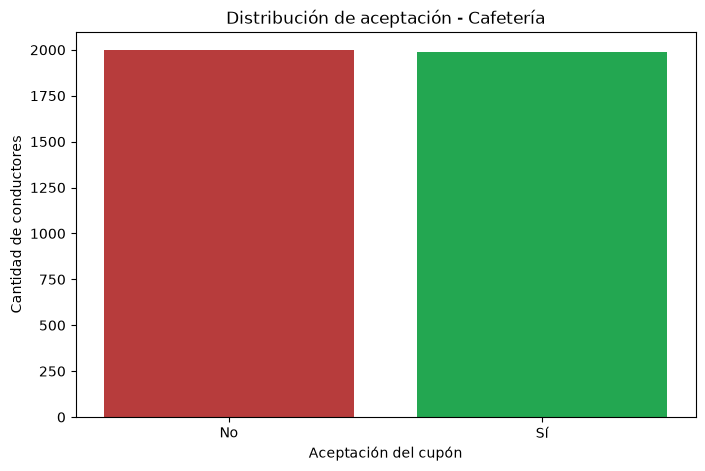

In [33]:
plt.figure(figsize=(8, 5))

plot_data = data_cafeteria['acepta_cupon'].value_counts()

x = plot_data.index
y = plot_data.values

plt.bar(x, y, color=["#B73C3C", "#23A751"])

plt.xlabel("Aceptación del cupón")
plt.ylabel("Cantidad de conductores")
plt.title("Distribución de aceptación - Cafetería")

plt.show()

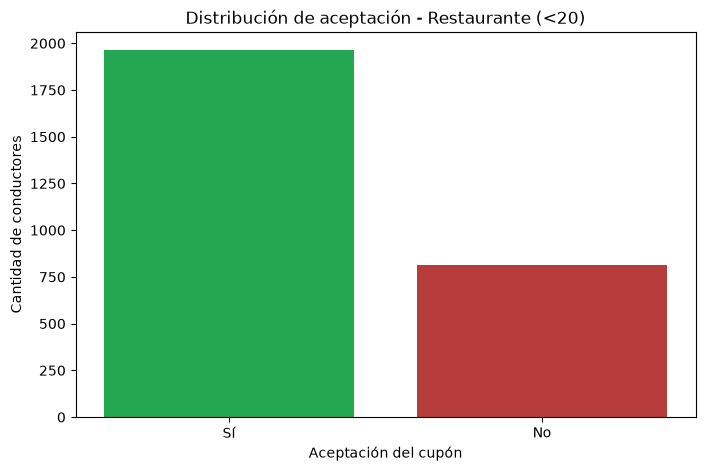

In [34]:
plt.figure(figsize=(8, 5))

plot_data = data_restaurante['acepta_cupon'].value_counts()

x = plot_data.index
y = plot_data.values

plt.bar(x, y, color=["#23A751", "#B73C3C"])

plt.xlabel("Aceptación del cupón")
plt.ylabel("Cantidad de conductores")
plt.title("Distribución de aceptación - Restaurante (<20)")

plt.show()

### 1.6. Distribución de la variable objetivo por tipo de cupón

Para Cafetería se identificaron 3.986 registros, de los cuales 1.989 corresponden a personas que aceptaron el cupón (49,9 %) y 1.997 a personas que lo rechazaron (50,1 %). Esto indica que las clases se encuentran prácticamente equilibradas.

Para Restaurante(<20) se identificaron 2.776 registros, de los cuales 1.962 corresponden a aceptación (70,7 %) y 814 a rechazo (29,3 %). En este caso se observa un desbalance a favor de la clase "Sí".

Esta diferencia es importante para el entrenamiento y la evaluación de los modelos, pues una mayor representación de una clase puede influir en las predicciones. Por esta razón, se evaluará el efecto de SMOTE en los modelos de Restaurante(<20), siguiendo lo estudiado en la práctica P9.

En ambos casos se utilizarán métricas de evaluación que permitan analizar el desempeño de los modelos más allá de la exactitud global.

In [35]:
data_cafeteria.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,3986,3986,3986,3986.000000,3986,3986,3986,3986,3986,3986,...,3914,3929,3936,3931,3986,3986,3986,3986,3986,3986
unique,3,4,3,NaN,5,1,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Cafetería,2 horas,Femenino,21,Soltero(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,No
freq,2151,2251,3459,NaN,1091,3986,2222,2045,882,1545,...,1073,1493,1677,1864,3986,2069,3676,3239,3239,1997
mean,NaN,NaN,NaN,68.026844,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,15.992518,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [36]:
data_restaurante.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,2776,2776,2776,2776.000000,2776,2776,2776,2776,2776,2776,...,2729,2742,2749,2733,2776,2776,2776,2776,2776,2776
unique,3,4,3,NaN,5,1,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Restaurante(<20),2 horas,Femenino,21,Casado(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,No,No,No,Sí,Sí
freq,1707,1431,2231,NaN,744,2776,1427,1417,569,1114,...,734,1018,1151,1328,2776,1535,2466,2275,2275,1962
mean,NaN,NaN,NaN,64.176873,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,19.790289,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.8. Análisis descriptivo de los subconjuntos

Se realizó un análisis descriptivo de los conjuntos de datos correspondientes a Cafetería y Restaurante(<20), utilizando estadísticas de tendencia central y frecuencia de las variables.

En ambos conjuntos, el destino más frecuente es "Sin lugar urgente", el acompañante más común es "Solo", el clima predominante es "Soleado" y la hora más frecuente es las 6:00 p. m.

La temperatura promedio es de 68,03 para Cafetería y 64,18 para Restaurante(<20), mientras que la mediana es de 80 en ambos conjuntos.

También se identifican diferencias en el estado civil más frecuente: "Soltero(a)" para Cafetería y "Casado(a)" para Restaurante(<20).

Estos resultados permiten describir las características generales de las observaciones. Sin embargo, será necesario continuar con la preparación y el modelado para evaluar la relación de las variables con la aceptación de los cupones.

In [37]:
# Valores faltantes - Cafetería
(data_cafeteria.isnull().sum() / data_cafeteria.shape[0]).sort_values(ascending=False)

vehiculo                           0.990718
frecuencia_cafeteria               0.018063
frecuencia_comida_para_llevar      0.014300
frecuencia_restaurante_20_a_50     0.013798
frecuencia_restaurante_menos_20    0.012544
frecuencia_bar                     0.009282
destino                            0.000000
acompanante                        0.000000
direccion_opuesta                  0.000000
misma_direccion                    0.000000
tiempo_cupon_mayor_25min           0.000000
tiempo_cupon_mayor_15min           0.000000
tiempo_cupon_mayor_5min            0.000000
ingreso                            0.000000
ocupacion                          0.000000
educacion                          0.000000
tiene_hijos                        0.000000
estado_civil                       0.000000
edad                               0.000000
genero                             0.000000
vigencia_cupon                     0.000000
cupon                              0.000000
hora                            

In [38]:
# Valores faltantes - Restaurante (<20)
(data_restaurante.isnull().sum() / data_restaurante.shape[0]).sort_values(ascending=False)

vehiculo                           0.990994
frecuencia_cafeteria               0.016931
frecuencia_restaurante_20_a_50     0.015490
frecuencia_comida_para_llevar      0.012248
frecuencia_restaurante_menos_20    0.009726
frecuencia_bar                     0.008285
destino                            0.000000
acompanante                        0.000000
direccion_opuesta                  0.000000
misma_direccion                    0.000000
tiempo_cupon_mayor_25min           0.000000
tiempo_cupon_mayor_15min           0.000000
tiempo_cupon_mayor_5min            0.000000
ingreso                            0.000000
ocupacion                          0.000000
educacion                          0.000000
tiene_hijos                        0.000000
estado_civil                       0.000000
edad                               0.000000
genero                             0.000000
vigencia_cupon                     0.000000
cupon                              0.000000
hora                            

### 1.9. Análisis de completitud por tipo de cupón

Se evaluó la proporción de valores faltantes en los conjuntos de Cafetería y Restaurante(<20).

En ambos casos, la variable `vehiculo` presenta más del 99 % de valores faltantes, lo que limita considerablemente su utilidad para el entrenamiento de los modelos.

Por otra parte, las variables relacionadas con la frecuencia de consumo presentan porcentajes de datos faltantes inferiores al 2 %, con pequeñas diferencias entre ambos conjuntos.

Debido a estos resultados, se considera pertinente evaluar la exclusión de la variable `vehiculo` y estudiar alternativas para tratar los valores faltantes de las variables de frecuencia de consumo, siguiendo los procedimientos de preparación de datos de la práctica P2.

Las decisiones definitivas de limpieza se tomarán en la siguiente etapa, buscando conservar información útil para la clasificación.

In [39]:
columnas_frecuencia = [
    'frecuencia_bar',
    'frecuencia_cafeteria',
    'frecuencia_comida_para_llevar',
    'frecuencia_restaurante_menos_20',
    'frecuencia_restaurante_20_a_50'
]

for columna in columnas_frecuencia:
    print("\nVariable:", columna)
    print("Cafetería:")
    print(data_cafeteria[columna].value_counts())
    print("Restaurante (<20):")
    print(data_restaurante[columna].value_counts())


Variable: frecuencia_bar
Cafetería:
frecuencia_bar
nunca         1634
menos de 1    1072
1 a 3          760
4 a 8          370
más de 8       113
Name: count, dtype: int64
Restaurante (<20):
frecuencia_bar
nunca         1118
menos de 1     761
1 a 3          557
4 a 8          238
más de 8        79
Name: count, dtype: int64

Variable: frecuencia_cafeteria
Cafetería:
frecuencia_cafeteria
menos de 1    1073
1 a 3         1038
nunca          925
4 a 8          537
más de 8       341
Name: count, dtype: int64
Restaurante (<20):
frecuencia_cafeteria
menos de 1    734
1 a 3         712
nunca         648
4 a 8         387
más de 8      248
Name: count, dtype: int64

Variable: frecuencia_comida_para_llevar
Cafetería:
frecuencia_comida_para_llevar
1 a 3         1493
4 a 8         1338
menos de 1     572
más de 8       484
nunca           42
Name: count, dtype: int64
Restaurante (<20):
frecuencia_comida_para_llevar
1 a 3         1018
4 a 8          949
menos de 1     396
más de 8       345
nun

In [40]:
for columna in columnas_frecuencia:
    print("Variable:", columna)
    print("Moda Cafetería:",
          data_cafeteria[columna].mode().iloc[0])
    print("Moda Restaurante:",
          data_restaurante[columna].mode().iloc[0])
    print()

Variable: frecuencia_bar
Moda Cafetería: nunca
Moda Restaurante: nunca

Variable: frecuencia_cafeteria
Moda Cafetería: menos de 1
Moda Restaurante: menos de 1

Variable: frecuencia_comida_para_llevar
Moda Cafetería: 1 a 3
Moda Restaurante: 1 a 3

Variable: frecuencia_restaurante_menos_20
Moda Cafetería: 1 a 3
Moda Restaurante: 1 a 3

Variable: frecuencia_restaurante_20_a_50
Moda Cafetería: menos de 1
Moda Restaurante: menos de 1



### 2. Preparación de datos

#### 2.1. Tratamiento de valores faltantes

Durante la exploración se identificaron valores faltantes en la variable `vehiculo` y en cinco variables relacionadas con la frecuencia de consumo.

La variable `vehiculo` presenta aproximadamente un 99 % de información faltante en ambos conjuntos, por lo que se propone excluirla del entrenamiento, debido a la escasa información disponible.

Para las variables de frecuencia de consumo se propone utilizar imputación por moda, siguiendo los procedimientos de la práctica P2. Esta alternativa permite conservar las observaciones y reemplazar los valores faltantes por la categoría más frecuente de cada variable.

El análisis mostró que las cinco variables presentan la misma moda en ambos subconjuntos. No obstante, se reconoce que este procedimiento puede incrementar la representación de las categorías más frecuentes.

In [41]:
cafeteria_limpio = data_cafeteria.copy()
restaurante_limpio = data_restaurante.copy()

cafeteria_limpio = cafeteria_limpio.drop(columns=['vehiculo'])
restaurante_limpio = restaurante_limpio.drop(columns=['vehiculo'])

print("Cafetería:", cafeteria_limpio.shape)
print("Restaurante:", restaurante_limpio.shape)

Cafetería: (3986, 25)
Restaurante: (2776, 25)


#### Identificación de variables sin variabilidad

Durante la exploración se identificó que las variables `cupon` y `tiempo_cupon_mayor_5min` presentan un único valor en cada uno de los subconjuntos analizados.

La variable `cupon` es constante porque los datos se separaron previamente según el tipo de establecimiento. Por su parte, `tiempo_cupon_mayor_5min` toma el valor "Sí" para todas las observaciones de ambos subconjuntos.

Debido a que estas características no permiten distinguir entre observaciones dentro de cada subconjunto, se propone excluirlas de las variables predictoras.

Esta decisión busca evitar incorporar características sin variabilidad y simplificar la preparación de los datos.

In [42]:
columnas_constantes = [
    'cupon',
    'tiempo_cupon_mayor_5min'
]

print("Cafetería:")
for columna in columnas_constantes:
    print(columna, cafeteria_limpio[columna].unique())

print("\nRestaurante (<20):")
for columna in columnas_constantes:
    print(columna, restaurante_limpio[columna].unique())

Cafetería:
cupon <ArrowStringArray>
['Cafetería']
Length: 1, dtype: str
tiempo_cupon_mayor_5min <ArrowStringArray>
['Sí']
Length: 1, dtype: str

Restaurante (<20):
cupon <ArrowStringArray>
['Restaurante(<20)']
Length: 1, dtype: str
tiempo_cupon_mayor_5min <ArrowStringArray>
['Sí']
Length: 1, dtype: str


#### Tratamiento de valores faltantes

Durante la exploración se observó que la variable `vehiculo` presenta aproximadamente un 99 % de valores faltantes en ambos subconjuntos. Por esta razón, se decidió excluirla del análisis.

Las variables relacionadas con la frecuencia de consumo presentan porcentajes de valores faltantes relativamente bajos. Inicialmente se consideró la imputación mediante la categoría más frecuente; sin embargo, para la implementación final se adoptó la estrategia presentada en la práctica P7.

En consecuencia, se utiliza `SimpleImputer` con la estrategia constante y el valor "Sin información" para las variables categóricas. La imputación se incorpora dentro del pipeline de preprocesamiento, de modo que sus transformaciones se ajusten exclusivamente con los datos de entrenamiento de cada partición.

Para las variables numéricas se utiliza imputación por mediana y estandarización mediante `StandardScaler`.

Este procedimiento permite mantener las observaciones con datos faltantes y conservar la separación entre entrenamiento y prueba.

### 2.2. Separación de variables predictoras y variable objetivo

Para cada tipo de cupón se separan las variables predictoras (X) y la variable objetivo (y).

La variable objetivo corresponde a `acepta_cupon`, que indica si el conductor aceptó o rechazó la oferta. Las variables predictoras contienen información sobre las características del conductor y las condiciones del viaje.

Esta separación permitirá preparar los datos y posteriormente entrenar los modelos de clasificación de manera independiente para cada tipo de cupón.

In [43]:
# Variables que no aportan información predictiva
columnas_excluir = [
    'acepta_cupon',
    'cupon',
    'tiempo_cupon_mayor_5min'
]

# Cafetería
X_cafeteria = cafeteria_limpio.drop(columns=columnas_excluir)
y_cafeteria = cafeteria_limpio['acepta_cupon']

# Restaurante (<20)
X_restaurante = restaurante_limpio.drop(columns=columnas_excluir)
y_restaurante = restaurante_limpio['acepta_cupon']

print("Cafetería:")
print(X_cafeteria.shape)
print(y_cafeteria.shape)

print("\nRestaurante (<20):")
print(X_restaurante.shape)
print(y_restaurante.shape)

Cafetería:
(3986, 22)
(3986,)

Restaurante (<20):
(2776, 22)
(2776,)


In [44]:
print("Columnas predictoras de Cafetería:")
print(X_cafeteria.shape)

print("\nColumnas predictoras de Restaurante:")
print(X_restaurante.shape)

Columnas predictoras de Cafetería:
(3986, 22)

Columnas predictoras de Restaurante:
(2776, 22)


### 2.3. División de los datos en entrenamiento y prueba

Se realiza una división de los datos para cada tipo de cupón, destinando el 80 % de las observaciones al entrenamiento y el 20 % a la evaluación de los modelos.

Se utiliza una división estratificada mediante `stratify=y` para conservar aproximadamente la proporción de aceptación y rechazo en ambos conjuntos.

Además, se establece `random_state=1` para garantizar la reproducibilidad de los resultados, siguiendo el procedimiento presentado en la práctica P7 de regresión logística.

Esta separación permite evaluar el desempeño de los modelos sobre observaciones que no fueron utilizadas durante su entrenamiento.

In [45]:
from sklearn.model_selection import train_test_split

# División de datos - Cafetería
X_train_caf, X_test_caf, y_train_caf, y_test_caf = train_test_split(
    X_cafeteria,
    y_cafeteria,
    test_size=0.2,
    random_state=1,
    stratify=y_cafeteria
)

# División de datos - Restaurante (<20)
X_train_res, X_test_res, y_train_res, y_test_res = train_test_split(
    X_restaurante,
    y_restaurante,
    test_size=0.2,
    random_state=1,
    stratify=y_restaurante
)

print("Cafetería:")
print("Entrenamiento:", X_train_caf.shape)
print("Prueba:", X_test_caf.shape)

print("\nRestaurante (<20):")
print("Entrenamiento:", X_train_res.shape)
print("Prueba:", X_test_res.shape)

Cafetería:
Entrenamiento: (3188, 22)
Prueba: (798, 22)

Restaurante (<20):
Entrenamiento: (2220, 22)
Prueba: (556, 22)


### 2.4. Identificación de variables numéricas y categóricas

Se identifican las variables predictoras de acuerdo con sus tipos de datos para aplicar las transformaciones correspondientes.

La variable `temperatura` es numérica, mientras que las demás variables predictoras son categóricas.

Esta distinción permitirá construir un preprocesador que aplique las transformaciones necesarias a cada grupo de variables, siguiendo el procedimiento de la práctica P7.

Las transformaciones se ajustarán utilizando únicamente el conjunto de entrenamiento para evitar que la información del conjunto de prueba influya en el aprendizaje del modelo.

In [46]:
numericas_features = ['temperatura']

categoricas_features = X_train_caf.select_dtypes(
    include=['object', 'str']
).columns.tolist()

print("Variables numéricas:")
print(numericas_features)

print("\nVariables categóricas:")
print(categoricas_features)

print("\nCantidad de variables categóricas:")
print(len(categoricas_features))

Variables numéricas:
['temperatura']

Variables categóricas:
['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon', 'genero', 'edad', 'estado_civil', 'tiene_hijos', 'educacion', 'ocupacion', 'ingreso', 'frecuencia_bar', 'frecuencia_cafeteria', 'frecuencia_comida_para_llevar', 'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min', 'misma_direccion', 'direccion_opuesta']

Cantidad de variables categóricas:
21


### 2.5. Construcción del preprocesador

Se construyen dos pipelines de transformación según el tipo de variable, siguiendo el procedimiento presentado en la práctica P7 de regresión logística.

Para las variables numéricas se utiliza `SimpleImputer` con la estrategia de mediana y posteriormente `StandardScaler`, con el fin de estandarizar sus valores.

Para las variables categóricas se utiliza `SimpleImputer` con la estrategia constante, asignando la categoría "Sin información" a los valores faltantes. Posteriormente se aplica `OneHotEncoder` para transformar las categorías en una representación numérica.

Se utiliza `ColumnTransformer` para integrar ambos procedimientos. Las transformaciones serán ajustadas durante el entrenamiento de los modelos para evitar utilizar información del conjunto de prueba.

In [47]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Transformación de variables numéricas
numerica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Transformación de variables categóricas
categorica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(
        strategy='constant',
        fill_value='Sin información'
    )),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

# Preprocesador
preprocesador = ColumnTransformer(
    transformers=[
        ('num', numerica_transformer, numericas_features),
        ('cat', categorica_transformer, categoricas_features)
    ]
)

### 3. Modelos de clasificación — Regresión logística

#### 3.1. Construcción del pipeline

Se utiliza un modelo de regresión logística para predecir la aceptación de los cupones, siguiendo el procedimiento presentado en la práctica P7.

El modelo se integra en un pipeline junto con las transformaciones definidas anteriormente. Esto permite que la preparación de los datos y el entrenamiento se realicen de forma consistente.

Se establece `max_iter=1000`, siguiendo la configuración de la práctica, para permitir un número suficiente de iteraciones durante la optimización del modelo.

Posteriormente se realizará una búsqueda de hiperparámetros mediante validación cruzada, explorando diferentes tipos de regularización y algoritmos de optimización (solvers), según lo solicitado en el enunciado.

In [48]:
from sklearn.linear_model import LogisticRegression

pipeline_rl = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', LogisticRegression(
        max_iter=1000
    ))
])

pipeline_rl

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

#### 3.2. Codificación de la variable objetivo

Para el entrenamiento y la evaluación de los modelos se transforma la variable objetivo `acepta_cupon` a una representación binaria.

Se asigna el valor 1 a la categoría "Sí" y el valor 0 a la categoría "No". De esta manera, la aceptación del cupón corresponde a la clase positiva, lo que facilitará la interpretación de las métricas de evaluación.

Esta transformación se aplica a los conjuntos de entrenamiento y prueba, conservando la separación realizada previamente.

In [49]:
# Codificación de la variable objetivo - Cafetería
y_train_caf = y_train_caf.map({'No': 0, 'Sí': 1})
y_test_caf = y_test_caf.map({'No': 0, 'Sí': 1})

# Codificación de la variable objetivo - Restaurante (<20)
y_train_res = y_train_res.map({'No': 0, 'Sí': 1})
y_test_res = y_test_res.map({'No': 0, 'Sí': 1})

print("Cafetería - Entrenamiento:")
print(y_train_caf.value_counts())

print("\nRestaurante (<20) - Entrenamiento:")
print(y_train_res.value_counts())

Cafetería - Entrenamiento:
acepta_cupon
0    1597
1    1591
Name: count, dtype: int64

Restaurante (<20) - Entrenamiento:
acepta_cupon
1    1569
0     651
Name: count, dtype: int64


### 3.3. Selección de hiperparámetros mediante validación cruzada

Para seleccionar la mejor configuración del modelo de regresión logística se utiliza `GridSearchCV`, siguiendo el procedimiento de la práctica P7.

Se exploran las regularizaciones L1 y L2, diferentes algoritmos de optimización y valores del parámetro C.

Se utiliza validación cruzada estratificada de 10 particiones mediante `StratifiedKFold`, para mantener aproximadamente la proporción de las clases durante la evaluación.

La selección se realizará utilizando el F1-score, que combina precisión y recall. Esto permite evaluar el desempeño del modelo considerando tanto los falsos positivos como los falsos negativos.

La búsqueda se realizará únicamente sobre el conjunto de entrenamiento de Cafetería, reservando el conjunto de prueba para la evaluación final.

In [50]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = [
    # Combinaciones válidas con L2
    {
        'modelo__penalty': ['l2'],
        'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear'],
        'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]
    },
    # Combinaciones válidas con L1
    {
        'modelo__penalty': ['l1'],
        'modelo__solver': ['liblinear'],
        'modelo__C': [0.1, 0.2, 0.5, 0.8, 1]
    }
]

kfold = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=0
)

In [51]:
grid_rl_caf = GridSearchCV(
    estimator=pipeline_rl,
    param_grid=param_grid,
    cv=kfold,
    scoring='f1',
    n_jobs=-1
)

grid_rl_caf

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance model

### 3.4. Entrenamiento del modelo de regresión logística — Cafetería

Se entrena el modelo de regresión logística utilizando el conjunto de entrenamiento de Cafetería.

Mediante `GridSearchCV` se evalúan las diferentes combinaciones de hiperparámetros definidas anteriormente. La selección se realiza utilizando el F1-score promedio de la validación cruzada estratificada.

El preprocesamiento se ejecuta dentro del pipeline, lo cual permite ajustar las transformaciones con los datos correspondientes a cada partición de entrenamiento y evita utilizar información del conjunto de prueba durante el entrenamiento.

In [52]:
grid_rl_caf.fit(X_train_caf, y_train_caf)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance model

In [53]:
print("Mejores hiperparámetros:")
print(grid_rl_caf.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_rl_caf.best_score_)

Mejores hiperparámetros:
{'modelo__C': 0.1, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}

Mejor F1-score de validación cruzada:
0.7275918568853605


### 3.5. Resultados de la búsqueda de hiperparámetros — Cafetería

La búsqueda de hiperparámetros mediante `GridSearchCV` identificó como mejor configuración del modelo de regresión logística la regularización L1, el parámetro C=0.1 y el algoritmo de optimización `liblinear`.

Esta configuración obtuvo un F1-score promedio de 0,7276 durante la validación cruzada estratificada de 10 particiones.

La regularización L1 penaliza los coeficientes del modelo y puede reducir algunos de ellos a cero, lo que contribuye a controlar su complejidad.

El resultado indica que esta fue la mejor configuración dentro de las combinaciones evaluadas. Sin embargo, es necesario comprobar su capacidad de generalización utilizando el conjunto de prueba que se reservó durante la división inicial.

### 3.6. Evaluación del modelo de regresión logística — Cafetería

Una vez seleccionada la mejor configuración mediante validación cruzada, se evalúa el modelo sobre el conjunto de prueba.

Se calculan las métricas de exactitud (accuracy), precisión (precision), sensibilidad (recall) y F1-score. Adicionalmente, se presenta la matriz de confusión para identificar las predicciones correctas e incorrectas de cada clase.

Esta evaluación permitirá analizar la capacidad de generalización del modelo y posteriormente comparar su desempeño con los demás algoritmos de clasificación.

In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predicciones del mejor modelo
y_pred_caf = grid_rl_caf.predict(X_test_caf)

# Métricas de evaluación
print("Accuracy:", accuracy_score(y_test_caf, y_pred_caf))
print("Precision:", precision_score(y_test_caf, y_pred_caf))
print("Recall:", recall_score(y_test_caf, y_pred_caf))
print("F1-score:", f1_score(y_test_caf, y_pred_caf))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_caf, y_pred_caf))

print("\nReporte de clasificación:")
print(classification_report(y_test_caf, y_pred_caf))

Accuracy: 0.7005012531328321
Precision: 0.6897374701670644
Recall: 0.7261306532663316
F1-score: 0.7074663402692778

Matriz de confusión:
[[270 130]
 [109 289]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.71      0.68      0.69       400
           1       0.69      0.73      0.71       398

    accuracy                           0.70       798
   macro avg       0.70      0.70      0.70       798
weighted avg       0.70      0.70      0.70       798



### 3.7. Análisis de resultados — Regresión logística para Cafetería

El modelo de regresión logística obtuvo un accuracy de 0,7005, precision de 0,6897, recall de 0,7261 y F1-score de 0,7075 sobre el conjunto de prueba.

El F1-score obtenido es ligeramente inferior al alcanzado durante la validación cruzada (0,7276), con una diferencia aproximada de 0,0201. Esto muestra una disminución moderada del desempeño al evaluar el modelo sobre observaciones no utilizadas durante el entrenamiento.

La matriz de confusión muestra 270 verdaderos negativos, 289 verdaderos positivos, 130 falsos positivos y 109 falsos negativos. En total, el modelo clasificó correctamente 559 de las 798 observaciones.

El recall de 0,7261 indica que el modelo identificó correctamente aproximadamente el 72,61 % de los conductores que realmente aceptaron el cupón. Por su parte, la precision de 0,6897 indica que aproximadamente el 68,97 % de las predicciones positivas fueron correctas.

Estos resultados servirán como referencia para comparar el desempeño de la regresión logística con los árboles de decisión y Random Forest.

### 3.8. Regresión logística — Restaurante(<20) sin balanceo

Se construye un modelo de regresión logística para predecir la aceptación de cupones de Restaurante(<20), siguiendo el procedimiento utilizado para Cafetería.

El entrenamiento se realizará inicialmente sin técnicas de balanceo, con el propósito de obtener un resultado de referencia que permita evaluar posteriormente el efecto de SMOTE.

Se utilizará `GridSearchCV` con validación cruzada estratificada y F1-score como criterio de selección, conservando las configuraciones de hiperparámetros establecidas anteriormente.

In [55]:
# Regresión logística - Restaurante (<20)
grid_rl_res = GridSearchCV(
    estimator=pipeline_rl,
    param_grid=param_grid,
    cv=kfold,
    scoring='f1',
    n_jobs=-1
)

# Entrenamiento
grid_rl_res.fit(X_train_res, y_train_res)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance model

In [56]:
print("Mejores hiperparámetros:")
print(grid_rl_res.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_rl_res.best_score_)

Mejores hiperparámetros:
{'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'newton-cg'}

Mejor F1-score de validación cruzada:
0.8490743521132134


### 3.9. Resultados de la búsqueda de hiperparámetros — Restaurante(<20)

La búsqueda mediante GridSearchCV seleccionó como mejor configuración la regularización L2, C=0.1 y el algoritmo de optimización newton-cg.

Esta configuración obtuvo un F1-score promedio de 0,8491 durante la validación cruzada estratificada de 10 particiones.

Aunque este resultado supera el F1-score de validación cruzada obtenido para Cafetería (0,7276), los resultados no son directamente equivalentes debido a las diferencias en la distribución de las clases.

En particular, Restaurante(<20) presenta una mayor proporción de aceptación, por lo que será importante examinar la matriz de confusión y las métricas por clase, además de evaluar posteriormente el efecto del balanceo mediante SMOTE.

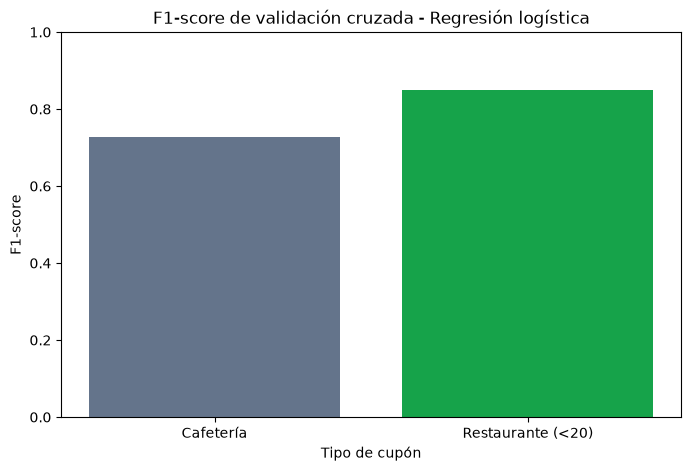

In [57]:
import matplotlib.pyplot as plt

modelos = ['Cafetería', 'Restaurante (<20)']
f1_scores = [
    grid_rl_caf.best_score_,
    grid_rl_res.best_score_
]

plt.figure(figsize=(8, 5))

plt.bar(modelos, f1_scores, color=['#64748B', '#16A34A'])

plt.title('F1-score de validación cruzada - Regresión logística')
plt.xlabel('Tipo de cupón')
plt.ylabel('F1-score')
plt.ylim(0, 1)

plt.show()

### 3.10. Evaluación del modelo de regresión logística — Restaurante(<20) sin SMOTE

Se evalúa el modelo seleccionado mediante validación cruzada sobre el conjunto de prueba de Restaurante(<20).

Se calculan accuracy, precision, recall y F1-score. Asimismo, se obtiene la matriz de confusión para analizar los errores de clasificación.

Debido al desbalance observado en la variable objetivo, se prestará especial atención a la capacidad del modelo para identificar tanto las aceptaciones como los rechazos, evitando interpretar su desempeño únicamente a partir de la exactitud global.

Estos resultados servirán como referencia para evaluar posteriormente el efecto de SMOTE.

In [58]:
# Predicciones - Restaurante (<20)
y_pred_res = grid_rl_res.predict(X_test_res)

print("Accuracy:", accuracy_score(y_test_res, y_pred_res))
print("Precision:", precision_score(y_test_res, y_pred_res))
print("Recall:", recall_score(y_test_res, y_pred_res))
print("F1-score:", f1_score(y_test_res, y_pred_res))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_res))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_res))

Accuracy: 0.7733812949640287
Precision: 0.7934065934065934
Recall: 0.9185750636132316
F1-score: 0.8514150943396226

Matriz de confusión:
[[ 69  94]
 [ 32 361]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.68      0.42      0.52       163
           1       0.79      0.92      0.85       393

    accuracy                           0.77       556
   macro avg       0.74      0.67      0.69       556
weighted avg       0.76      0.77      0.76       556



### 3.11. Análisis de resultados — Regresión logística para Restaurante(<20)

El modelo de regresión logística sin SMOTE obtuvo un accuracy de 0,7734, precision de 0,7934, recall de 0,9186 y F1-score de 0,8514 sobre el conjunto de prueba.

El F1-score fue ligeramente superior al obtenido durante la validación cruzada (0,8491), lo cual muestra un desempeño similar en ambas evaluaciones.

Sin embargo, el análisis por clase evidencia diferencias importantes. Para la clase positiva (aceptación), el modelo alcanza un recall de 0,9186, mientras que para la clase negativa (rechazo) el recall es aproximadamente 0,4233.

La matriz de confusión muestra 69 verdaderos negativos, 361 verdaderos positivos, 94 falsos positivos y 32 falsos negativos.

Estos resultados indican que el modelo tiene mayor capacidad para identificar aceptaciones que rechazos. Debido al desbalance entre las clases, será necesario evaluar si la aplicación de SMOTE mejora la identificación de los rechazos sin perjudicar excesivamente el desempeño general.

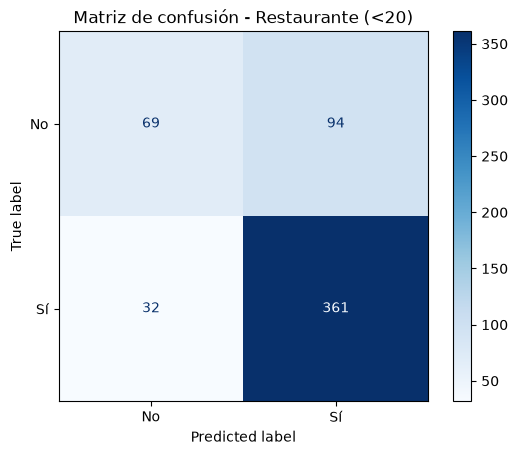

In [59]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz_res = confusion_matrix(y_test_res, y_pred_res)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_res,
    display_labels=['No', 'Sí']
)

disp.plot(cmap='Blues')

plt.title('Matriz de confusión - Restaurante (<20)')
plt.show()

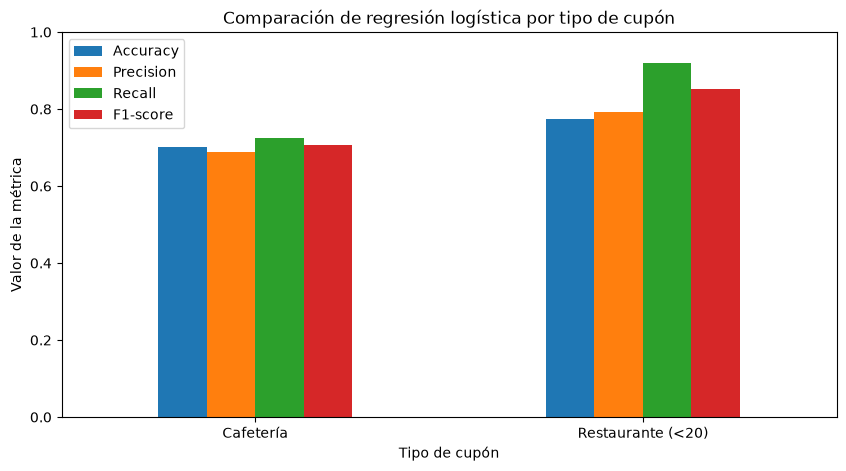

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

comparacion_rl = pd.DataFrame({
    'Modelo': ['Cafetería', 'Restaurante (<20)'],
    'Accuracy': [0.7005, 0.7734],
    'Precision': [0.6897, 0.7934],
    'Recall': [0.7261, 0.9186],
    'F1-score': [0.7075, 0.8514]
})

comparacion_rl.set_index('Modelo').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Comparación de regresión logística por tipo de cupón')
plt.ylabel('Valor de la métrica')
plt.xlabel('Tipo de cupón')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

### 3.12. Análisis gráfico de los modelos de regresión logística

La matriz de confusión del modelo de Restaurante(<20) muestra que se identificaron correctamente 361 aceptaciones y 69 rechazos. Sin embargo, 94 conductores que rechazaron el cupón fueron clasificados como posibles aceptaciones.

Esto evidencia que el modelo presenta un mejor desempeño para la clase positiva que para la negativa.

La comparación gráfica entre Cafetería y Restaurante(<20) muestra que el segundo modelo obtiene valores superiores de accuracy, precision, recall y F1-score para la clase positiva.

No obstante, esta diferencia debe interpretarse considerando el desbalance de clases del conjunto Restaurante(<20), donde las aceptaciones representan aproximadamente el 70,7 % de las observaciones.

Por esta razón, se evaluará posteriormente el efecto del balanceo de clases sobre el desempeño predictivo, especialmente sobre la identificación de los rechazos.

### 3.13. Tratamiento del desbalance de clases mediante SMOTE

El conjunto de Restaurante(<20) presenta un desbalance entre las clases de aceptación y rechazo. El modelo de regresión logística sin balanceo obtuvo un recall de aproximadamente 0,42 para los rechazos, frente a 0,92 para las aceptaciones.

Por esta razón, se propone experimentar con SMOTE para evaluar si mejora la identificación de la clase minoritaria.

Siguiendo la práctica P9, SMOTE se incorporará dentro de un pipeline de `imblearn`, de manera que el balanceo se aplique únicamente a los datos de entrenamiento de cada partición de validación cruzada.

Dado que el conjunto incluye variables categóricas codificadas mediante OneHotEncoder, se tendrá en cuenta que el uso de SMOTE convencional sobre esta representación puede producir valores sintéticos que no correspondan exactamente a categorías originales.

In [61]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### 3.14. Construcción del pipeline con SMOTE

Se construye un pipeline que integra el preprocesamiento de los datos, el balanceo mediante SMOTE y el modelo de regresión logística.

SMOTE genera observaciones sintéticas de la clase minoritaria a partir de ejemplos existentes. Su aplicación dentro del pipeline permite realizar el balanceo exclusivamente sobre los datos de entrenamiento de cada partición de validación cruzada, evitando la fuga de información hacia los datos de validación o prueba.

El modelo resultante se comparará con la regresión logística entrenada sin balanceo, prestando especial atención al F1-score y al recall de la clase minoritaria.

Como las variables categóricas fueron transformadas mediante OneHotEncoder, se reconoce que SMOTE convencional puede generar valores intermedios entre categorías codificadas. Esta limitación se tendrá en cuenta al interpretar los resultados.

In [62]:
pipeline_rl_smote = ImbPipeline(steps=[
    ('preprocesador', preprocesador),
    ('smote', SMOTE(random_state=1)),
    ('modelo', LogisticRegression(max_iter=1000))
])

pipeline_rl_smote

,steps,"[('preprocesador', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for format

### 3.15. Selección de hiperparámetros con SMOTE

Se realiza una búsqueda de hiperparámetros para el modelo de regresión logística con SMOTE, utilizando GridSearchCV y validación cruzada estratificada de 10 particiones.

Se mantienen las combinaciones de hiperparámetros exploradas en el modelo sin balanceo, con el fin de facilitar la comparación entre ambos procedimientos.

SMOTE se encuentra integrado dentro del pipeline para generar observaciones sintéticas únicamente a partir de los datos de entrenamiento correspondientes a cada partición.

La selección de hiperparámetros se realizará utilizando el F1-score de la clase positiva. Posteriormente se evaluarán también el F1-score macro y el recall de la clase minoritaria, para determinar si el balanceo mejora la identificación de los rechazos.

In [63]:
grid_rl_res_smote = GridSearchCV(
    estimator=pipeline_rl_smote,
    param_grid=param_grid,
    cv=kfold,
    scoring='f1',
    n_jobs=-1
)

grid_rl_res_smote

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance model

In [64]:
grid_rl_res_smote.fit(X_train_res, y_train_res)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l2'], 'modelo__solver': ['newton-cg', 'lbfgs', ...]}, {'modelo__C': [0.1, 0.2, ...], 'modelo__penalty': ['l1'], 'modelo__solver': ['liblinear']}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance model

In [65]:
print("Mejores hiperparámetros con SMOTE:")
print(grid_rl_res_smote.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_rl_res_smote.best_score_)

Mejores hiperparámetros con SMOTE:
{'modelo__C': 0.2, 'modelo__penalty': 'l1', 'modelo__solver': 'liblinear'}

Mejor F1-score de validación cruzada:
0.7893848882781633


### 3.16. Resultados de la búsqueda de hiperparámetros con SMOTE

La búsqueda de hiperparámetros para el modelo de regresión logística con SMOTE seleccionó la regularización L1, C=0.2 y el algoritmo liblinear.

La configuración obtuvo un F1-score promedio de 0,7894 mediante validación cruzada estratificada de 10 particiones.

Este resultado es inferior al F1-score de validación cruzada obtenido por el modelo sin balanceo (0,8491).

Sin embargo, esta diferencia corresponde al F1-score de la clase positiva (aceptación). Por lo tanto, todavía no es posible determinar si SMOTE mejoró la identificación de la clase minoritaria, correspondiente a los rechazos.

Para establecerlo, será necesario evaluar ambos modelos sobre el mismo conjunto de prueba y comparar las métricas por clase, especialmente el recall de los rechazos y el F1-score macro.

### 3.17. Evaluación del modelo con SMOTE — Restaurante(<20)

Se evalúa el modelo de regresión logística entrenado con SMOTE sobre el conjunto de prueba original, que no fue balanceado ni utilizado durante el entrenamiento.

Se calculan las métricas accuracy, precision, recall y F1-score, junto con el reporte de clasificación y la matriz de confusión.

Esta evaluación permitirá comparar el desempeño del modelo con y sin balanceo, considerando especialmente su capacidad para identificar los rechazos de cupones.

In [66]:
# Predicciones del modelo con SMOTE
y_pred_res_smote = grid_rl_res_smote.predict(X_test_res)

print("Accuracy:", accuracy_score(y_test_res, y_pred_res_smote))
print("Precision:", precision_score(y_test_res, y_pred_res_smote))
print("Recall:", recall_score(y_test_res, y_pred_res_smote))
print("F1-score:", f1_score(y_test_res, y_pred_res_smote))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_res_smote))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_res_smote))

Accuracy: 0.7338129496402878
Precision: 0.855072463768116
Recall: 0.7506361323155216
F1-score: 0.7994579945799458

Matriz de confusión:
[[113  50]
 [ 98 295]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.54      0.69      0.60       163
           1       0.86      0.75      0.80       393

    accuracy                           0.73       556
   macro avg       0.70      0.72      0.70       556
weighted avg       0.76      0.73      0.74       556



### 3.18. Comparación del desempeño con y sin SMOTE

Se comparan los resultados de los modelos de regresión logística de Restaurante(<20), entrenados con y sin SMOTE, utilizando el mismo conjunto de prueba.

Se consideran tres métricas: el F1-score de la clase positiva, el F1-score macro y el recall de la clase minoritaria.

Esta comparación permite determinar si la mejora en la identificación de rechazos compensa la posible disminución del desempeño en la predicción de aceptaciones.

                Sin SMOTE  Con SMOTE
F1-score (Sí)    0.851415   0.799458
F1-score macro   0.687071   0.701868
Recall (No)      0.423313   0.693252


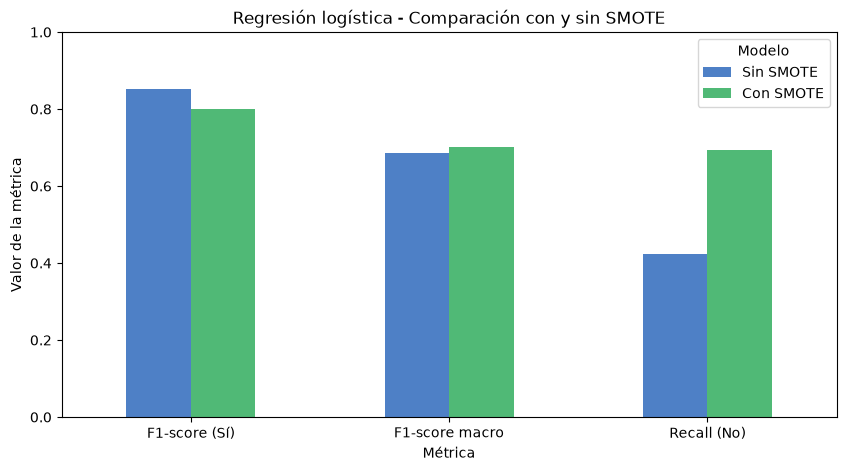

In [67]:
from sklearn.metrics import f1_score, recall_score
import pandas as pd
import matplotlib.pyplot as plt

comparacion_smote = pd.DataFrame({
    'Sin SMOTE': [
        f1_score(y_test_res, y_pred_res),
        f1_score(y_test_res, y_pred_res, average='macro'),
        recall_score(y_test_res, y_pred_res, pos_label=0)
    ],
    'Con SMOTE': [
        f1_score(y_test_res, y_pred_res_smote),
        f1_score(y_test_res, y_pred_res_smote, average='macro'),
        recall_score(y_test_res, y_pred_res_smote, pos_label=0)
    ]
}, index=[
    'F1-score (Sí)',
    'F1-score macro',
    'Recall (No)'
])

print(comparacion_smote)

comparacion_smote.plot(
    kind='bar',
    figsize=(10, 5),
    color=["#4E80C6", "#50B976"]
)

plt.title('Regresión logística - Comparación con y sin SMOTE')
plt.ylabel('Valor de la métrica')
plt.xlabel('Métrica')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Modelo')
plt.show()

### 3.19. Análisis del efecto de SMOTE

La aplicación de SMOTE mejoró la capacidad del modelo para identificar la clase minoritaria, correspondiente a los rechazos de los cupones.

El recall de los rechazos aumentó de 0,4233 a 0,6933, lo que representa una mejora de aproximadamente 27 puntos porcentuales. El número de rechazos correctamente identificados pasó de 69 a 113.

Por otra parte, el F1-score de la clase positiva disminuyó de 0,8514 a 0,7995 y el accuracy pasó de 0,7734 a 0,7338. Esto indica que la mejora en la identificación de rechazos tuvo como contrapartida una reducción en el desempeño general del modelo.

El F1-score macro aumentó ligeramente, de aproximadamente 0,6871 a 0,7019, lo que refleja una mejora en el equilibrio del desempeño entre las dos clases.

En conclusión, SMOTE resultó útil para reconocer una mayor proporción de rechazos, aunque no mejoró todas las métricas. Su conveniencia dependerá de la importancia que tenga para Ruta Alpes evitar ofrecer cupones a conductores que probablemente no los aceptarán, frente al riesgo de dejar de ofrecerlos a posibles clientes.

Adicionalmente, los resultados deben interpretarse considerando la limitación de aplicar SMOTE convencional sobre variables categóricas previamente codificadas mediante OneHotEncoder, ya que los registros sintéticos generados pueden no representar combinaciones categóricas reales.

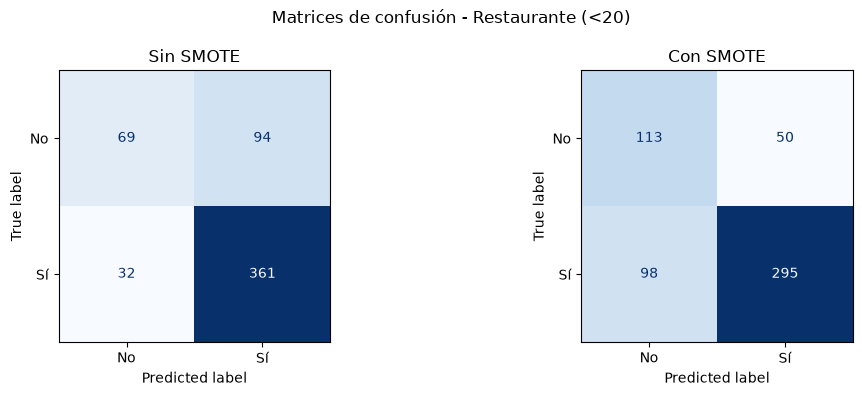

In [68]:
from sklearn.metrics import ConfusionMatrixDisplay

matriz_sin_smote = confusion_matrix(y_test_res, y_pred_res)
matriz_con_smote = confusion_matrix(y_test_res, y_pred_res_smote)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    matriz_sin_smote,
    display_labels=['No', 'Sí']
).plot(ax=axes[0], cmap='Blues', colorbar=False)

axes[0].set_title('Sin SMOTE')

ConfusionMatrixDisplay(
    matriz_con_smote,
    display_labels=['No', 'Sí']
).plot(ax=axes[1], cmap='Blues', colorbar=False)

axes[1].set_title('Con SMOTE')

plt.suptitle('Matrices de confusión - Restaurante (<20)')
plt.tight_layout()
plt.show()

### 4. Modelos de clasificación — Árboles de decisión

#### 4.1. Construcción del pipeline

Se utilizarán árboles de decisión para predecir la aceptación de cupones de Cafetería y Restaurante(<20), siguiendo el procedimiento presentado en la práctica P8.

Este algoritmo construye reglas de clasificación a partir de las características de las observaciones, buscando particiones que permitan distinguir entre las clases de aceptación y rechazo.

Se integra el árbol con el preprocesador definido anteriormente mediante un pipeline. Posteriormente, se realizará una búsqueda de hiperparámetros para controlar la complejidad del modelo y mejorar su capacidad de generalización.

In [69]:
from sklearn.tree import DecisionTreeClassifier

pipeline_arbol = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', DecisionTreeClassifier(random_state=1))
])

pipeline_arbol

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

#### 4.2. Selección de hiperparámetros mediante validación cruzada

Para seleccionar la configuración del árbol de decisión se utiliza GridSearchCV con validación cruzada estratificada de 10 particiones.

Se exploran diferentes valores de profundidad máxima (`max_depth`), número mínimo de muestras por hoja (`min_samples_leaf`) y criterio de partición (`criterion`).

La selección se realizará mediante el F1-score de la clase positiva, manteniendo el mismo criterio utilizado en los modelos de regresión logística.

El objetivo es encontrar una configuración que permita distinguir entre aceptaciones y rechazos, controlando al mismo tiempo la complejidad del árbol.

In [70]:
param_grid_arbol = {
    'modelo__max_depth': [3, 5, 7, 10, 15],
    'modelo__min_samples_leaf': [1, 5, 10, 20],
    'modelo__criterion': ['gini', 'entropy']
}

grid_arbol_caf = GridSearchCV(
    estimator=pipeline_arbol,
    param_grid=param_grid_arbol,
    cv=kfold,
    scoring='f1',
    n_jobs=-1
)

grid_arbol_caf

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__criterion': ['gini', 'entropy'], 'modelo__max_depth': [3, 5, ...], 'modelo__min_samples_leaf': [1, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

#### 4.3. Entrenamiento del árbol de decisión — Cafetería

Se entrena un árbol de decisión para predecir la aceptación de cupones de Cafetería utilizando el conjunto de entrenamiento.

Mediante GridSearchCV se evalúan 40 combinaciones de hiperparámetros con validación cruzada estratificada de 10 particiones.

La selección se realiza a partir del F1-score promedio de la clase positiva. Las transformaciones de los datos se ejecutan dentro del pipeline, evitando utilizar información del conjunto de prueba durante el entrenamiento.

El conjunto de prueba se mantiene reservado para evaluar posteriormente la capacidad de generalización del mejor árbol y comparar su desempeño con la regresión logística.

In [71]:
# Entrenamiento del árbol de decisión - Cafetería
grid_arbol_caf.fit(X_train_caf, y_train_caf)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...om_state=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__criterion': ['gini', 'entropy'], 'modelo__max_depth': [3, 5, ...], 'modelo__min_samples_leaf': [1, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

In [72]:
print("Mejores hiperparámetros:")
print(grid_arbol_caf.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_arbol_caf.best_score_)

Mejores hiperparámetros:
{'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 1}

Mejor F1-score de validación cruzada:
0.7227353527159182


#### 4.4. Resultados de la búsqueda de hiperparámetros — Cafetería

La búsqueda de hiperparámetros mediante GridSearchCV seleccionó como mejor configuración del árbol de decisión el criterio Gini, una profundidad máxima de 5 y un mínimo de 1 observación por hoja.

Esta configuración obtuvo un F1-score promedio de 0,7227 durante la validación cruzada estratificada de 10 particiones.

El resultado es ligeramente inferior al obtenido por el modelo de regresión logística para Cafetería (0,7276). Sin embargo, la diferencia es pequeña y corresponde únicamente a la validación cruzada.

Por tanto, será necesario evaluar el árbol sobre el conjunto de prueba para comparar su desempeño predictivo y determinar si representa una alternativa adecuada para este tipo de cupón.

#### 4.5. Evaluación del árbol de decisión — Cafetería

Una vez seleccionados los mejores hiperparámetros mediante validación cruzada, se evalúa el árbol de decisión utilizando las 798 observaciones del conjunto de prueba de Cafetería.

Se calculan las métricas accuracy, precision, recall y F1-score, junto con la matriz de confusión y el reporte de clasificación.

Los resultados permitirán evaluar la capacidad de generalización del árbol y compararlo con la regresión logística entrenada anteriormente.

In [73]:
# Predicciones del árbol de decisión - Cafetería
y_pred_arbol_caf = grid_arbol_caf.predict(X_test_caf)

print("Accuracy:", accuracy_score(y_test_caf, y_pred_arbol_caf))
print("Precision:", precision_score(y_test_caf, y_pred_arbol_caf))
print("Recall:", recall_score(y_test_caf, y_pred_arbol_caf))
print("F1-score:", f1_score(y_test_caf, y_pred_arbol_caf))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_caf, y_pred_arbol_caf))

print("\nReporte de clasificación:")
print(classification_report(y_test_caf, y_pred_arbol_caf))

Accuracy: 0.7030075187969925
Precision: 0.6930455635491607
Recall: 0.7261306532663316
F1-score: 0.7092024539877301

Matriz de confusión:
[[272 128]
 [109 289]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.71      0.68      0.70       400
           1       0.69      0.73      0.71       398

    accuracy                           0.70       798
   macro avg       0.70      0.70      0.70       798
weighted avg       0.70      0.70      0.70       798



#### 4.6. Análisis de resultados — Árbol de decisión para Cafetería

El árbol de decisión obtuvo un accuracy de 0,7030, precision de 0,6930, recall de 0,7261 y F1-score de 0,7092 sobre el conjunto de prueba.

El F1-score es ligeramente inferior al obtenido durante la validación cruzada (0,7227), lo cual muestra una pequeña disminución del desempeño al evaluar el modelo con observaciones no utilizadas durante el entrenamiento.

La matriz de confusión registra 272 verdaderos negativos, 289 verdaderos positivos, 128 falsos positivos y 109 falsos negativos.

Al comparar estos resultados con la regresión logística, se observa que el árbol presenta un F1-score ligeramente superior (0,7092 frente a 0,7075). Sin embargo, la diferencia es pequeña y ambos modelos obtienen el mismo recall de aceptación.

Por tanto, no se identifica todavía una ventaja predictiva importante de uno de los algoritmos sobre el otro. Posteriormente, estos resultados se compararán con Random Forest para seleccionar el modelo más adecuado.

#### 4.7. Visualización de las reglas del árbol de decisión — Cafetería

Se visualizan los primeros niveles del árbol de decisión seleccionado mediante validación cruzada.

Esta representación permite identificar las variables utilizadas en las primeras divisiones y comprender cómo se construyen las reglas para clasificar la aceptación o rechazo de los cupones.

Aunque el árbol fue entrenado con una profundidad máxima de cinco niveles, se muestran únicamente los primeros tres para facilitar la interpretación gráfica.

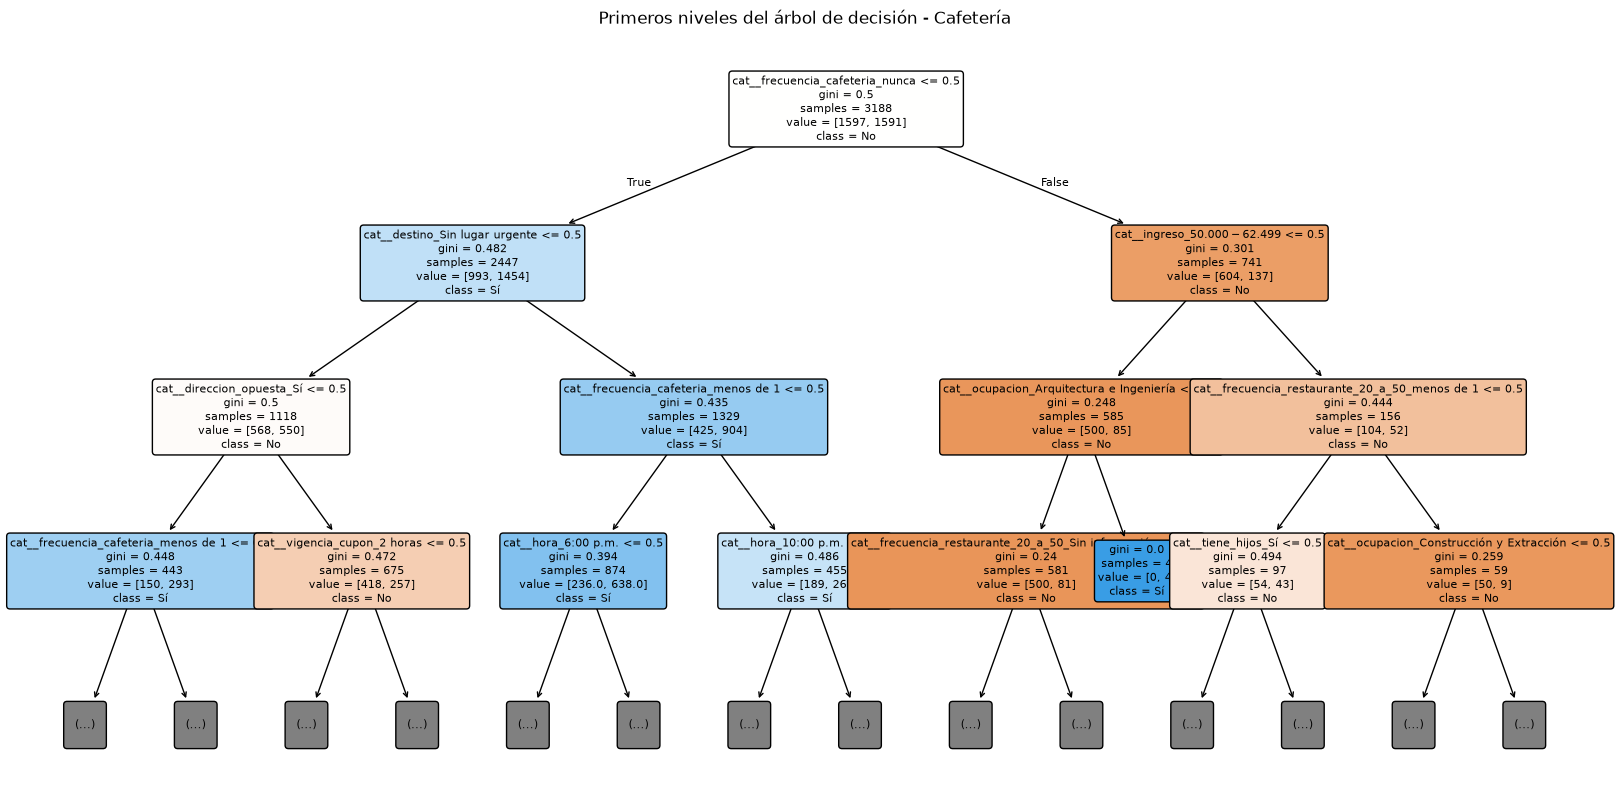

In [74]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Recuperar el mejor pipeline
mejor_arbol_caf = grid_arbol_caf.best_estimator_

# Recuperar el árbol entrenado
arbol_caf = mejor_arbol_caf.named_steps['modelo']

# Recuperar los nombres de variables transformadas
nombres_variables_caf = (
    mejor_arbol_caf.named_steps['preprocesador']
    .get_feature_names_out()
)

plt.figure(figsize=(20, 10))

plot_tree(
    arbol_caf,
    feature_names=nombres_variables_caf,
    class_names=['No', 'Sí'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title('Primeros niveles del árbol de decisión - Cafetería')
plt.show()

#### 4.8. Interpretación de las reglas del árbol de decisión — Cafetería

La visualización del árbol de decisión muestra que la primera variable utilizada para dividir las observaciones es la frecuencia de visitas a cafeterías, específicamente la categoría "nunca".

Entre los conductores que indicaron que nunca visitan cafeterías, 137 de 741 aceptaron el cupón, lo que corresponde aproximadamente al 18,5 %. En cambio, entre quienes registraron otra frecuencia de visita, 1.454 de 2.447 aceptaron el cupón, aproximadamente el 59,4 %.

Esto sugiere que los hábitos previos de consumo son relevantes para predecir la aceptación de cupones de Cafetería.

En los siguientes niveles aparecen variables relacionadas con la urgencia del destino, la dirección del establecimiento, la frecuencia de consumo, la vigencia del cupón y la hora del día.

Estas divisiones muestran que el modelo combina información sobre los hábitos del conductor y las condiciones del desplazamiento. Sin embargo, las relaciones identificadas son predictivas y no deben interpretarse necesariamente como relaciones causales.

La visualización corresponde únicamente a los primeros niveles del árbol. Para identificar las características con mayor influencia global se analizará posteriormente la importancia de variables.

#### 4.9. Importancia de variables — Árbol de decisión para Cafetería

Se analiza la importancia de las variables utilizadas por el árbol de decisión mediante el atributo `feature_importances_`.

Esta medida representa la contribución relativa de cada característica a la reducción de impureza durante la construcción del árbol.

Se visualizan las diez características transformadas con mayor importancia para identificar los factores que más contribuyen a las predicciones del modelo.

Estos resultados permitirán complementar la interpretación de las reglas y analizar cuáles características del conductor y del contexto son más relevantes para la aceptación de cupones.

cat__frecuencia_cafeteria_nunca         0.449124
cat__destino_Sin lugar urgente          0.113242
cat__direccion_opuesta_Sí               0.099299
cat__frecuencia_cafeteria_menos de 1    0.089594
cat__vigencia_cupon_2 horas             0.057435
cat__hora_10:00 p.m.                    0.031699
cat__hora_6:00 p.m.                     0.022171
cat__ingreso_$50.000 - $62.499          0.020524
cat__tiempo_cupon_mayor_15min_Sí        0.015402
cat__tiene_hijos_Sí                     0.015224
dtype: float64


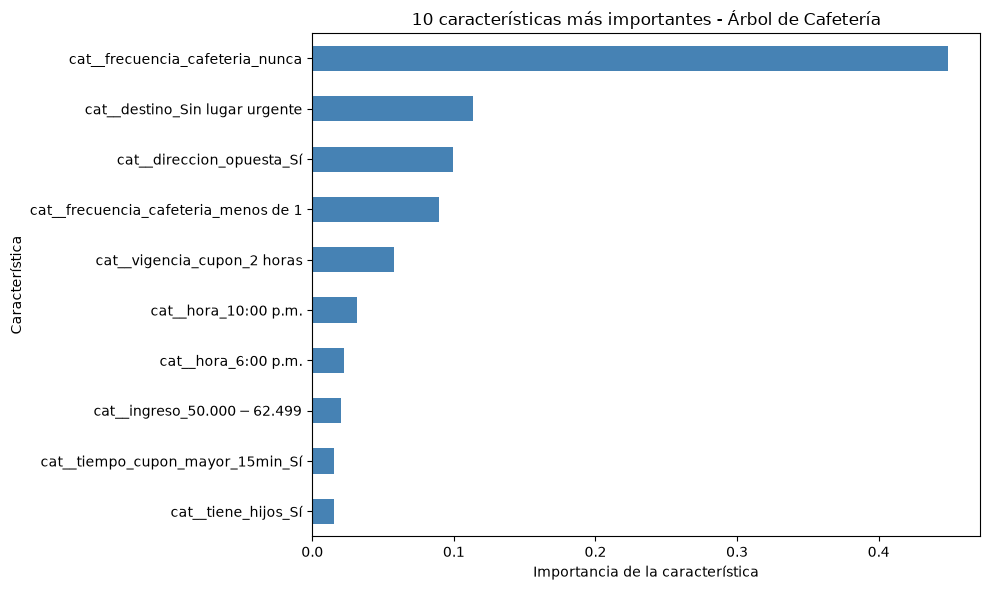

In [75]:
import pandas as pd
import matplotlib.pyplot as plt

# Importancia de las variables del árbol
importancias_caf = pd.Series(
    arbol_caf.feature_importances_,
    index=nombres_variables_caf
)

# Seleccionar las 10 características más importantes
top_importancias_caf = importancias_caf.sort_values(
    ascending=False
).head(10)

print(top_importancias_caf)

# Visualización
plt.figure(figsize=(10, 6))

top_importancias_caf.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('10 características más importantes - Árbol de Cafetería')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 4.10. Análisis de importancia de variables — Cafetería

El análisis de importancia de características del árbol de decisión muestra que la categoría `frecuencia_cafeteria_nunca` presenta la mayor contribución a las decisiones del modelo, con una importancia de 0,4491.

Le siguen las características `destino_Sin lugar urgente` (0,1132), `direccion_opuesta_Sí` (0,0993), `frecuencia_cafeteria_menos de 1` (0,0896) y `vigencia_cupon_2 horas` (0,0574).

Las categorías relacionadas con la frecuencia de visitas a cafeterías se encuentran entre las características más importantes del árbol. Esto sugiere que los hábitos previos de consumo tienen un papel relevante en las predicciones de aceptación.

También aparecen variables relacionadas con las condiciones del recorrido, como la urgencia del destino y la dirección del establecimiento, así como características de la oferta, como la vigencia del cupón.

Estos resultados permiten identificar factores predictivos relevantes para Ruta Alpes. Sin embargo, las importancias corresponden a la reducción de impureza dentro del árbol y no deben interpretarse como efectos causales ni como cambios directos en la probabilidad de aceptación.

Además, debido a la codificación OneHotEncoder, las importancias se presentan por categoría y no necesariamente por variable original completa.

### 4.11. Árbol de decisión — Restaurante(<20)

Se entrena un árbol de decisión para predecir la aceptación de cupones de Restaurante(<20).

Se utiliza un pipeline con las mismas transformaciones aplicadas al modelo de Cafetería y se realiza una búsqueda de hiperparámetros mediante GridSearchCV y validación cruzada estratificada de 10 particiones.

Se exploran diferentes profundidades máximas, cantidades mínimas de muestras por hoja y criterios de partición. El modelo se selecciona utilizando el F1-score de la clase positiva.

El entrenamiento se realiza inicialmente sin SMOTE, manteniendo la distribución original de las clases. Posteriormente, el modelo se evaluará sobre el conjunto de prueba para comparar su desempeño con los demás algoritmos.

In [76]:
# Búsqueda de hiperparámetros - Árbol de Restaurante (<20)
grid_arbol_res = GridSearchCV(
    estimator=pipeline_arbol,
    param_grid=param_grid_arbol,
    cv=kfold,
    scoring='f1',
    n_jobs=-1
)

# Entrenamiento
grid_arbol_res.fit(X_train_res, y_train_res)

print("Mejores hiperparámetros:")
print(grid_arbol_res.best_params_)

print("\nMejor F1-score de validación cruzada:")
print(grid_arbol_res.best_score_)

Mejores hiperparámetros:
{'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10}

Mejor F1-score de validación cruzada:
0.8454102083563585


#### 4.12. Resultados de la búsqueda de hiperparámetros — Restaurante(<20)

La búsqueda de hiperparámetros mediante GridSearchCV seleccionó como mejor configuración del árbol de decisión el criterio Gini, una profundidad máxima de 3 niveles y un mínimo de 10 observaciones por hoja.

Esta configuración obtuvo un F1-score promedio de 0,8454 durante la validación cruzada estratificada de 10 particiones.

El resultado es ligeramente inferior al obtenido por la regresión logística sin SMOTE (0,8491), aunque la diferencia es pequeña.

La profundidad máxima de 3 y el mínimo de 10 observaciones por hoja limitan la complejidad del árbol, lo que puede contribuir a reducir el riesgo de sobreajuste.

Debido al desbalance de clases de Restaurante(<20), será necesario analizar el rendimiento por clase y la matriz de confusión, especialmente para determinar qué tan bien identifica el modelo los rechazos.

#### 4.13. Evaluación del árbol de decisión — Restaurante(<20)

Se evalúa el árbol de decisión seleccionado mediante validación cruzada utilizando el conjunto de prueba de Restaurante(<20).

Se calculan accuracy, precision, recall y F1-score, junto con la matriz de confusión y el reporte de clasificación.

Dado el desbalance entre las clases de aceptación y rechazo, se analizará especialmente el recall de la clase negativa para determinar si el árbol identifica correctamente los conductores que rechazan los cupones.

Los resultados se compararán posteriormente con los modelos de regresión logística.

In [77]:
# Predicciones del árbol de decisión - Restaurante (<20)
y_pred_arbol_res = grid_arbol_res.predict(X_test_res)

print("Accuracy:", accuracy_score(y_test_res, y_pred_arbol_res))
print("Precision:", precision_score(y_test_res, y_pred_arbol_res))
print("Recall:", recall_score(y_test_res, y_pred_arbol_res))
print("F1-score:", f1_score(y_test_res, y_pred_arbol_res))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_arbol_res))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_arbol_res))

Accuracy: 0.7589928057553957
Precision: 0.7626774847870182
Recall: 0.9567430025445293
F1-score: 0.8487584650112867

Matriz de confusión:
[[ 46 117]
 [ 17 376]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.73      0.28      0.41       163
           1       0.76      0.96      0.85       393

    accuracy                           0.76       556
   macro avg       0.75      0.62      0.63       556
weighted avg       0.75      0.76      0.72       556



#### 4.14. Análisis de resultados — Árbol de decisión para Restaurante(<20)

El árbol de decisión obtuvo un accuracy de 0,7590, precision de 0,7627, recall de 0,9567 y F1-score de 0,8488 sobre el conjunto de prueba.

El F1-score obtenido es cercano al resultado de validación cruzada (0,8454), lo que indica un desempeño similar en ambas evaluaciones.

La matriz de confusión muestra 46 verdaderos negativos, 376 verdaderos positivos, 117 falsos positivos y 17 falsos negativos.

Aunque el modelo identifica correctamente aproximadamente el 95,67 % de las aceptaciones, solamente reconoce el 28,22 % de los rechazos.

Esto evidencia una dificultad importante para clasificar la clase minoritaria, posiblemente relacionada con el desbalance del conjunto de datos.

Al compararlo con la regresión logística sin SMOTE, se observa que el árbol obtiene un recall de aceptación superior, pero presenta resultados inferiores en accuracy, F1-score de aceptación y recall de rechazo.

Por tanto, aunque el árbol permite interpretar las reglas de clasificación, hasta el momento no ofrece una mejora general frente a la regresión logística para Restaurante(<20).

#### 4.15. Visualización del árbol de decisión — Restaurante(<20)

Se visualiza el árbol de decisión completo para identificar las principales reglas utilizadas en la predicción de aceptación de cupones de Restaurante(<20).

Debido a que el modelo seleccionado tiene una profundidad máxima de tres niveles, es posible representar su estructura completa y analizar cómo utiliza las características del conductor y del contexto para realizar las clasificaciones.

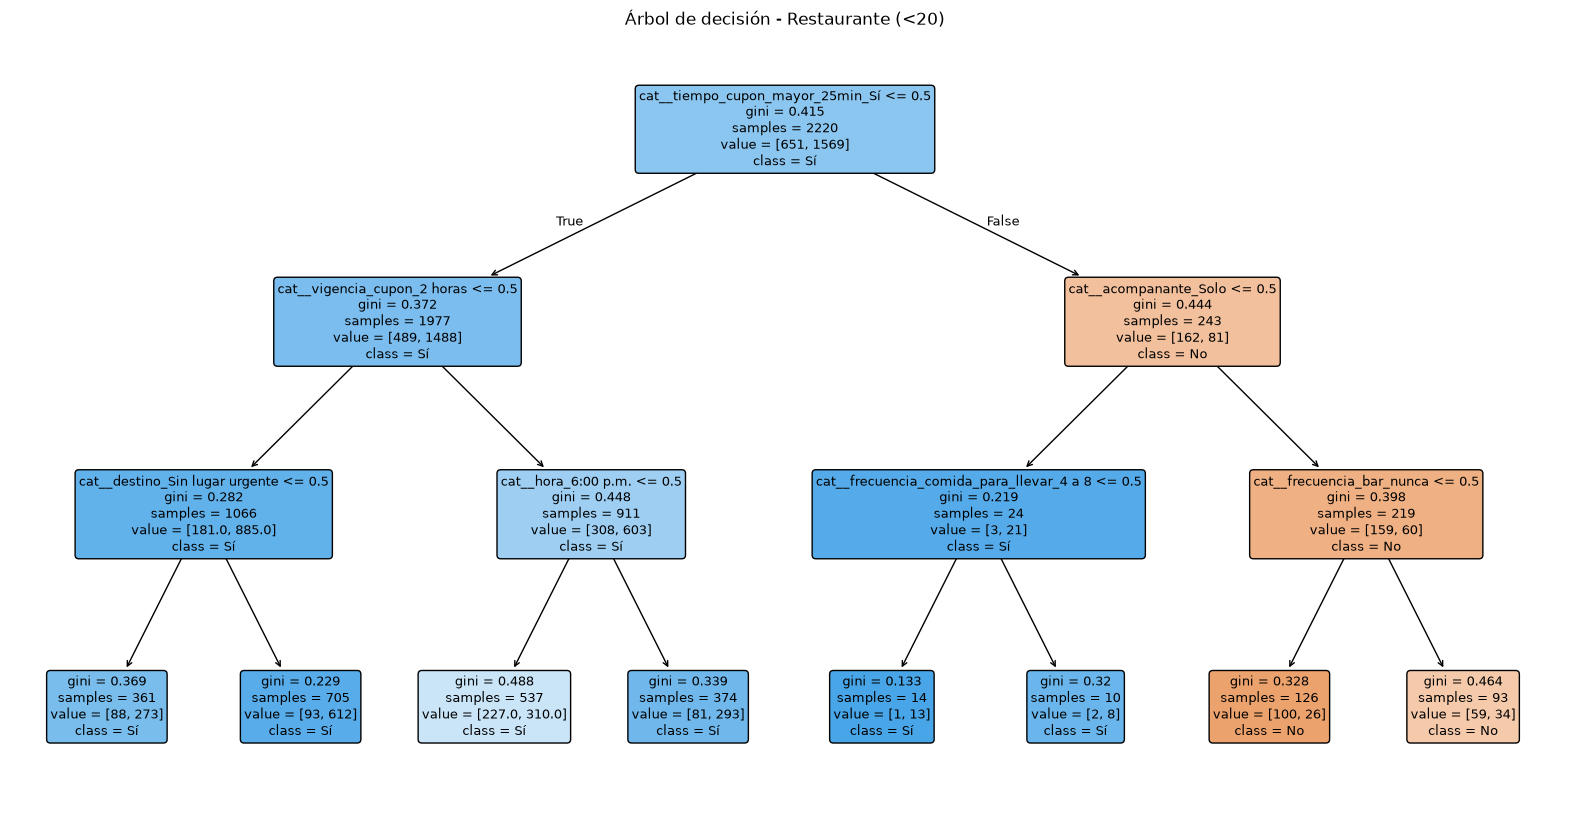

In [78]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Recuperar el mejor pipeline
mejor_arbol_res = grid_arbol_res.best_estimator_

# Recuperar el árbol entrenado
arbol_res = mejor_arbol_res.named_steps['modelo']

# Recuperar los nombres de las características transformadas
nombres_variables_res = (
    mejor_arbol_res.named_steps['preprocesador']
    .get_feature_names_out()
)

plt.figure(figsize=(20, 10))

plot_tree(
    arbol_res,
    feature_names=nombres_variables_res,
    class_names=['No', 'Sí'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Árbol de decisión - Restaurante (<20)')
plt.show()

#### 4.16. Interpretación de las reglas del árbol de decisión — Restaurante(<20)

La visualización del árbol de decisión muestra que la primera característica utilizada para dividir las observaciones es si el tiempo de desplazamiento hacia el establecimiento supera los 25 minutos.

Entre los 1.977 conductores para quienes el desplazamiento no supera ese límite, 1.488 aceptaron el cupón, lo que representa aproximadamente el 75,3 %. Por el contrario, entre los 243 conductores cuyo desplazamiento supera los 25 minutos, solamente 81 aceptaron el cupón, aproximadamente el 33,3 %.

Esto sugiere que el tiempo necesario para llegar al establecimiento constituye un factor predictivo relevante.

En las siguientes divisiones se identifican características relacionadas con la vigencia del cupón, el destino, la hora del día, los acompañantes y los hábitos de consumo.

En particular, para los conductores con desplazamientos superiores a 25 minutos, el árbol considera si viajan solos y posteriormente otras características de consumo.

La mayoría de las hojas del árbol predicen aceptación, lo cual resulta coherente con el desbalance de clases observado en el conjunto Restaurante(<20). Esto también contribuye a explicar el bajo recall obtenido para los rechazos.

Las reglas identificadas muestran asociaciones predictivas entre las características observadas y la aceptación de cupones, pero no permiten establecer relaciones causales.

#### 4.17. Importancia de variables — Árbol de decisión para Restaurante(<20)

Se calcula la importancia de las características utilizadas por el árbol de decisión de Restaurante(<20), mediante el atributo `feature_importances_`.

Se visualizan las diez características transformadas con mayor importancia para identificar los factores que contribuyen a las decisiones del modelo.

Esta información permitirá comparar las variables relevantes para Restaurante(<20) con las identificadas en Cafetería y analizar las diferencias entre ambos tipos de cupones.

cat__tiempo_cupon_mayor_25min_Sí            0.517092
cat__vigencia_cupon_2 horas                 0.189073
cat__hora_6:00 p.m.                         0.127312
cat__acompanante_Solo                       0.106182
cat__destino_Sin lugar urgente              0.040592
cat__frecuencia_bar_nunca                   0.018439
cat__frecuencia_comida_para_llevar_4 a 8    0.001310
cat__ingreso_$62.500 - $74.999              0.000000
cat__frecuencia_bar_más de 8                0.000000
cat__frecuencia_bar_menos de 1              0.000000
dtype: float64


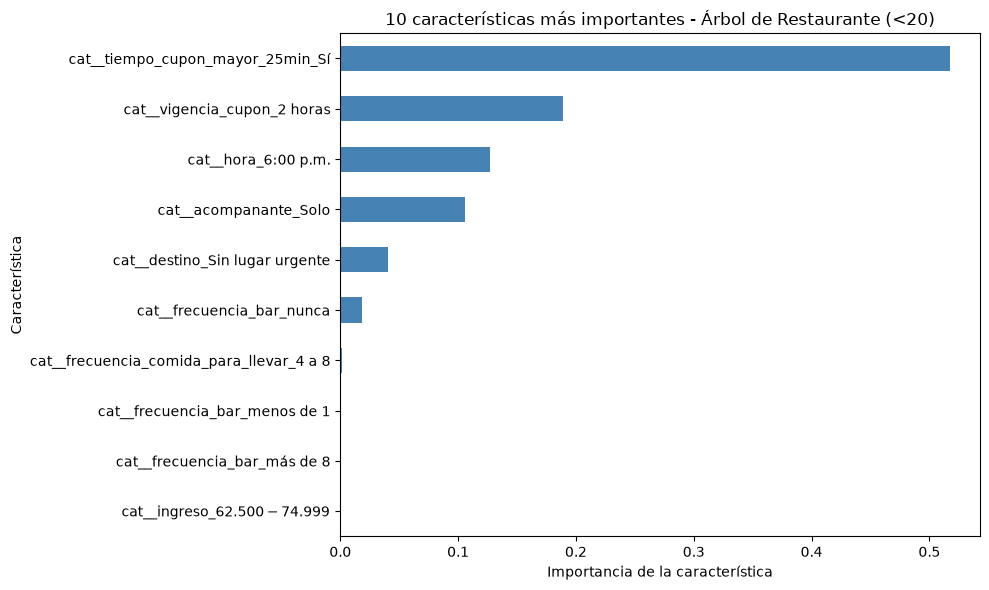

In [79]:
# Importancia de variables - Árbol Restaurante (<20)
importancias_res = pd.Series(
    arbol_res.feature_importances_,
    index=nombres_variables_res
)

top_importancias_res = importancias_res.sort_values(
    ascending=False
).head(10)

print(top_importancias_res)

plt.figure(figsize=(10, 6))

top_importancias_res.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('10 características más importantes - Árbol de Restaurante (<20)')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 4.18. Análisis de importancia de variables — Restaurante(<20)

El análisis de importancia de características del árbol de decisión muestra que la variable `tiempo_cupon_mayor_25min_Sí` presenta la mayor contribución a las decisiones del modelo, con una importancia de 0,5171.

Le siguen `vigencia_cupon_2 horas` (0,1891), `hora_6:00 p.m.` (0,1273), `acompanante_Solo` (0,1062) y `destino_Sin lugar urgente` (0,0406).

Las primeras cuatro características concentran aproximadamente el 93,97 % de la importancia total del árbol. Esto indica que el modelo utiliza principalmente características relacionadas con el tiempo de desplazamiento, la duración del cupón, la hora y los acompañantes.

Al comparar estos resultados con Cafetería, se observa una diferencia en las características seleccionadas. En Cafetería, la frecuencia de visitas al establecimiento tiene un papel predominante, mientras que en Restaurante(<20) destaca el tiempo necesario para llegar.

Estas diferencias sugieren que los patrones predictivos pueden variar según el tipo de cupón.

No obstante, las importancias se calculan mediante reducción de impureza, por lo que no deben interpretarse como relaciones causales. Asimismo, la existencia de características correlacionadas puede afectar la distribución de las importancias.

### 5. Modelos de clasificación — Random Forest

#### 5.1. Construcción del pipeline

Se desarrollarán dos modelos de clasificación mediante Random Forest: uno para los cupones de Cafetería y otro para los cupones de Restaurante(<20).

Random Forest es un algoritmo de ensamble que combina múltiples árboles de decisión. Su objetivo es obtener predicciones más robustas al agregar las decisiones de distintos árboles.

Para implementar los modelos, se utilizará `RandomForestClassifier` dentro de un pipeline que incorpora el preprocesamiento definido anteriormente. De esta manera, la imputación y la codificación de características se realizarán dentro de cada partición de entrenamiento durante la validación cruzada.

Posteriormente, se utilizará `GridSearchCV` para explorar el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el número mínimo de muestras por hoja (`min_samples_leaf`).

In [80]:
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', RandomForestClassifier(random_state=1))
])

pipeline_rf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesador', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

In [81]:
print("Cafetería:", X_train_caf.shape)
print("Restaurante:", X_train_res.shape)

print("Variables numéricas:", len(numericas_features))
print("Variables categóricas:", len(categoricas_features))

print("Valores faltantes en y_train_caf:",
      y_train_caf.isna().sum())

print("Valores faltantes en y_train_res:",
      y_train_res.isna().sum())

Cafetería: (3188, 22)
Restaurante: (2220, 22)
Variables numéricas: 1
Variables categóricas: 21
Valores faltantes en y_train_caf: 0
Valores faltantes en y_train_res: 0


#### 5.2. Búsqueda de hiperparámetros — Random Forest para Cafetería

Para seleccionar la mejor configuración del modelo Random Forest correspondiente a los cupones de Cafetería, se utiliza `GridSearchCV` con validación cruzada estratificada de diez particiones.

Se exploran tres hiperparámetros: el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el número mínimo de muestras por hoja (`min_samples_leaf`).

Se utiliza el F1-score de la clase positiva como métrica de selección, buscando equilibrar la precisión y el recall en la predicción de aceptación del cupón.

El proceso se desarrolla dentro de un pipeline que incluye las transformaciones de preprocesamiento, con el fin de evitar utilizar información del conjunto de prueba durante el ajuste del modelo.

In [82]:
# Hiperparámetros de Random Forest
param_grid_rf = {
    'modelo__n_estimators': [50, 100, 200],
    'modelo__max_depth': [5, 10, 15],
    'modelo__min_samples_leaf': [1, 5, 10]
}

# Búsqueda de hiperparámetros para Cafetería
grid_rf_caf = GridSearchCV(
    pipeline_rf,
    param_grid=param_grid_rf,
    cv=kfold,
    scoring='f1',
    n_jobs=-1
)

# Entrenar el modelo
grid_rf_caf.fit(X_train_caf, y_train_caf)

# Mostrar resultados
print("Mejores hiperparámetros:")
print(grid_rf_caf.best_params_)

print("\nMejor F1-score en validación cruzada:")
print(grid_rf_caf.best_score_)

Mejores hiperparámetros:
{'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 50}

Mejor F1-score en validación cruzada:
0.7695130310752438


#### 5.3. Resultados de la búsqueda de hiperparámetros — Cafetería

La búsqueda de hiperparámetros mediante `GridSearchCV`, con validación cruzada estratificada de diez particiones, seleccionó una configuración de Random Forest con 50 árboles (`n_estimators=50`), profundidad máxima de 15 (`max_depth=15`) y un mínimo de una muestra por hoja (`min_samples_leaf=1`).

El mejor F1-score promedio en validación cruzada fue de 0,7695.

Este resultado indica que, entre las configuraciones evaluadas, dicha combinación presentó el mejor equilibrio entre precision y recall para la clase positiva.

A continuación, se evaluará el modelo seleccionado sobre el conjunto de prueba, que no participó en la búsqueda de hiperparámetros, para analizar su desempeño en observaciones no utilizadas durante el entrenamiento.

#### 5.4. Evaluación de Random Forest — Cafetería

Se evalúa el mejor modelo de Random Forest sobre el conjunto de prueba de Cafetería.

Para medir su desempeño, se calculan accuracy, precision, recall y F1-score. También se genera la matriz de confusión y el reporte de clasificación, con el propósito de analizar los errores cometidos en las clases de aceptación y rechazo.

Esta evaluación permitirá comparar posteriormente Random Forest con los modelos de regresión logística y árbol de decisión.

In [83]:
# Predicciones sobre el conjunto de prueba
y_pred_rf_caf = grid_rf_caf.predict(X_test_caf)

# Métricas de evaluación
print("Accuracy:", accuracy_score(y_test_caf, y_pred_rf_caf))
print("Precision:", precision_score(y_test_caf, y_pred_rf_caf))
print("Recall:", recall_score(y_test_caf, y_pred_rf_caf))
print("F1-score:", f1_score(y_test_caf, y_pred_rf_caf))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_caf, y_pred_rf_caf))

print("\nReporte de clasificación:")
print(classification_report(y_test_caf, y_pred_rf_caf))

Accuracy: 0.7431077694235589
Precision: 0.7238979118329466
Recall: 0.7839195979899497
F1-score: 0.752714113389626

Matriz de confusión:
[[281 119]
 [ 86 312]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.77      0.70      0.73       400
           1       0.72      0.78      0.75       398

    accuracy                           0.74       798
   macro avg       0.74      0.74      0.74       798
weighted avg       0.74      0.74      0.74       798



#### 5.5. Análisis de resultados — Random Forest para Cafetería

El modelo Random Forest obtuvo un accuracy de 0,7431, precision de 0,7239, recall de 0,7839 y F1-score de 0,7527 sobre el conjunto de prueba.

El F1-score de validación cruzada fue de 0,7695, mientras que el obtenido sobre el conjunto de prueba fue de 0,7527. La diferencia de aproximadamente 0,017 puntos indica que el desempeño disminuyó ligeramente al evaluar observaciones no utilizadas durante el entrenamiento.

La matriz de confusión muestra 281 verdaderos negativos, 312 verdaderos positivos, 119 falsos positivos y 86 falsos negativos.

El modelo identificó correctamente el 78,39 % de las aceptaciones y el 70,25 % de los rechazos. Esta distribución evidencia un desempeño relativamente equilibrado entre ambas clases, aunque mantiene una mayor capacidad para identificar aceptaciones.

Los resultados sugieren que Random Forest es una alternativa prometedora para la clasificación de cupones de Cafetería. Sin embargo, su selección como mejor algoritmo deberá realizarse después de comparar los tres modelos utilizando la misma preparación de datos y el mismo conjunto de prueba.

#### 5.6. Visualización de la matriz de confusión — Random Forest para Cafetería

Se presenta gráficamente la matriz de confusión del modelo Random Forest para facilitar la identificación de predicciones correctas y errores de clasificación.

La visualización permite distinguir verdaderos negativos, falsos positivos, falsos negativos y verdaderos positivos, y será utilizada posteriormente en la comparación con los demás algoritmos.

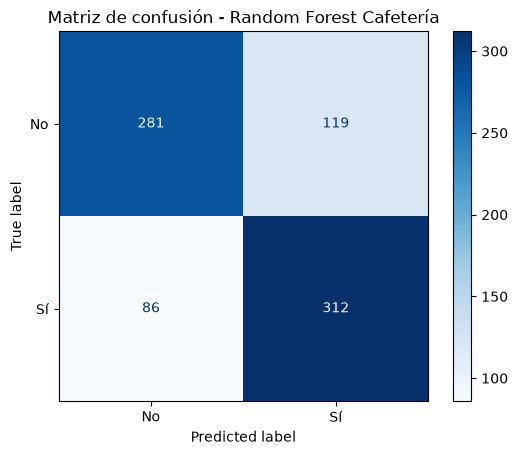

In [84]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_caf,
    y_pred_rf_caf,
    display_labels=['No', 'Sí'],
    cmap='Blues'
)

plt.title('Matriz de confusión - Random Forest Cafetería')
plt.show()

#### 5.7. Búsqueda de hiperparámetros — Random Forest para Restaurante(<20)

Se desarrolla un modelo Random Forest para predecir la aceptación de cupones de Restaurante(<20).

Al igual que en Cafetería, se utiliza un pipeline que incorpora las transformaciones de preprocesamiento y el clasificador `RandomForestClassifier`.

La búsqueda de hiperparámetros se realiza mediante `GridSearchCV`, utilizando validación cruzada estratificada de diez particiones. Se exploran el número de árboles (`n_estimators`), la profundidad máxima (`max_depth`) y el número mínimo de muestras por hoja (`min_samples_leaf`).

Se utiliza el F1-score de la clase positiva como métrica de selección. Posteriormente, el mejor modelo será evaluado en el conjunto de prueba para determinar su capacidad de generalización y analizar su desempeño en ambas clases.

In [85]:
# Búsqueda de hiperparámetros para Restaurante (<20)
grid_rf_res = GridSearchCV(
    pipeline_rf,
    param_grid=param_grid_rf,
    cv=kfold,
    scoring='f1',
    n_jobs=-1
)

# Entrenar el modelo
grid_rf_res.fit(X_train_res, y_train_res)

# Mostrar resultados
print("Mejores hiperparámetros:")
print(grid_rf_res.best_params_)

print("\nMejor F1-score en validación cruzada:")
print(grid_rf_res.best_score_)

Mejores hiperparámetros:
{'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 50}

Mejor F1-score en validación cruzada:
0.8599686454278732


#### 5.8. Resultados de la búsqueda de hiperparámetros — Restaurante(<20)

La búsqueda de hiperparámetros mediante `GridSearchCV`, con validación cruzada estratificada de diez particiones, seleccionó una configuración de Random Forest con 50 árboles (`n_estimators=50`), profundidad máxima de 15 (`max_depth=15`) y un mínimo de una muestra por hoja (`min_samples_leaf=1`).

El mejor F1-score promedio en validación cruzada fue de 0,8600.

Esta configuración coincide con la seleccionada para Cafetería. Sin embargo, el F1-score de Restaurante es superior, diferencia que debe interpretarse considerando la distinta distribución de las clases en ambos subconjuntos.

Dado que Restaurante(<20) presenta un desbalance hacia la clase de aceptación, es importante complementar el F1-score de la clase positiva con la evaluación de la clase minoritaria.

A continuación, se evaluará el modelo sobre el conjunto de prueba, prestando especial atención a su capacidad para identificar los rechazos.

#### 5.9. Evaluación de Random Forest — Restaurante(<20)

Se evalúa el mejor modelo de Random Forest para Restaurante(<20) sobre el conjunto de prueba.

Se calculan accuracy, precision, recall y F1-score, junto con la matriz de confusión y el reporte de clasificación.

Además del desempeño de la clase positiva, se analiza el recall y el F1-score de los rechazos, debido al desbalance presente en este subconjunto.

Estos resultados permitirán comparar Random Forest con regresión logística y árboles de decisión y evaluar si presenta una mejora en la clasificación de ambas clases.

In [86]:
# Predicciones de Random Forest para Restaurante (<20)
y_pred_rf_res = grid_rf_res.predict(X_test_res)

# Métricas de evaluación
print("Accuracy:", accuracy_score(y_test_res, y_pred_rf_res))
print("Precision:", precision_score(y_test_res, y_pred_rf_res))
print("Recall:", recall_score(y_test_res, y_pred_rf_res))
print("F1-score:", f1_score(y_test_res, y_pred_rf_res))

print("\nMatriz de confusión:")
print(confusion_matrix(y_test_res, y_pred_rf_res))

print("\nReporte de clasificación:")
print(classification_report(y_test_res, y_pred_rf_res))

Accuracy: 0.7841726618705036
Precision: 0.8013245033112583
Recall: 0.9236641221374046
F1-score: 0.8581560283687943

Matriz de confusión:
[[ 73  90]
 [ 30 363]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.71      0.45      0.55       163
           1       0.80      0.92      0.86       393

    accuracy                           0.78       556
   macro avg       0.76      0.69      0.70       556
weighted avg       0.77      0.78      0.77       556



#### 5.10. Análisis de resultados — Random Forest para Restaurante(<20)

El modelo Random Forest obtuvo un accuracy de 0,7842, precision de 0,8013, recall de 0,9237 y F1-score de 0,8582 sobre el conjunto de prueba.

El F1-score promedio obtenido mediante validación cruzada fue de 0,8600, por lo que el desempeño en prueba resultó muy cercano al estimado durante la selección de hiperparámetros.

La matriz de confusión muestra 73 verdaderos negativos, 363 verdaderos positivos, 90 falsos positivos y 30 falsos negativos.

El modelo identificó correctamente el 92,37 % de las aceptaciones, pero únicamente el 44,79 % de los rechazos.

Estos resultados muestran que Random Forest tiene una buena capacidad para identificar la clase positiva; sin embargo, su desempeño sobre la clase minoritaria sigue siendo limitado.

El F1-score macro fue aproximadamente 0,70, inferior al F1-score de la clase positiva, lo cual refleja las diferencias en el desempeño entre ambas clases.

Por tanto, además de considerar el F1-score de aceptación, será importante evaluar el recall de los rechazos y los efectos del balanceo mediante SMOTE antes de seleccionar el modelo definitivo.

#### 5.11. Visualización de la matriz de confusión — Random Forest para Restaurante(<20)

Se representa gráficamente la matriz de confusión del modelo Random Forest para Restaurante(<20).

La visualización permite identificar las predicciones correctas y los errores de clasificación, especialmente los falsos positivos correspondientes a conductores que rechazaron el cupón, pero fueron clasificados como posibles aceptantes.

Esta información será utilizada en la comparación de los modelos y en el análisis del desbalance de clases.

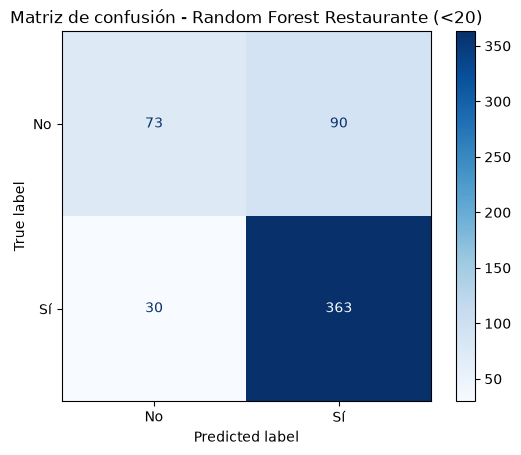

In [87]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_res,
    y_pred_rf_res,
    display_labels=['No', 'Sí'],
    cmap='Blues'
)

plt.title('Matriz de confusión - Random Forest Restaurante (<20)')
plt.show()

#### 5.12. Importancia de características — Random Forest para Cafetería

Para identificar las características más relevantes en la predicción de aceptación de cupones de Cafetería, se calcula la importancia de las variables del mejor modelo Random Forest.

Se utiliza el atributo `feature_importances_`, que mide la contribución relativa de cada característica a la reducción de impureza de los árboles del ensamble.

Posteriormente, se representan gráficamente las diez características transformadas con mayor importancia.

Este análisis permitirá comparar los patrones identificados por Random Forest con los obtenidos previamente mediante árboles de decisión. Las importancias no deben interpretarse como relaciones causales.

cat__frecuencia_cafeteria_nunca             0.105636
cat__vigencia_cupon_2 horas                 0.038041
cat__destino_Sin lugar urgente              0.032055
num__temperatura                            0.027824
cat__tiempo_cupon_mayor_15min_Sí            0.023475
cat__hora_6:00 p.m.                         0.022800
cat__frecuencia_cafeteria_4 a 8             0.020383
cat__frecuencia_cafeteria_menos de 1        0.020231
cat__acompanante_Solo                       0.018237
cat__frecuencia_comida_para_llevar_4 a 8    0.017401
dtype: float64


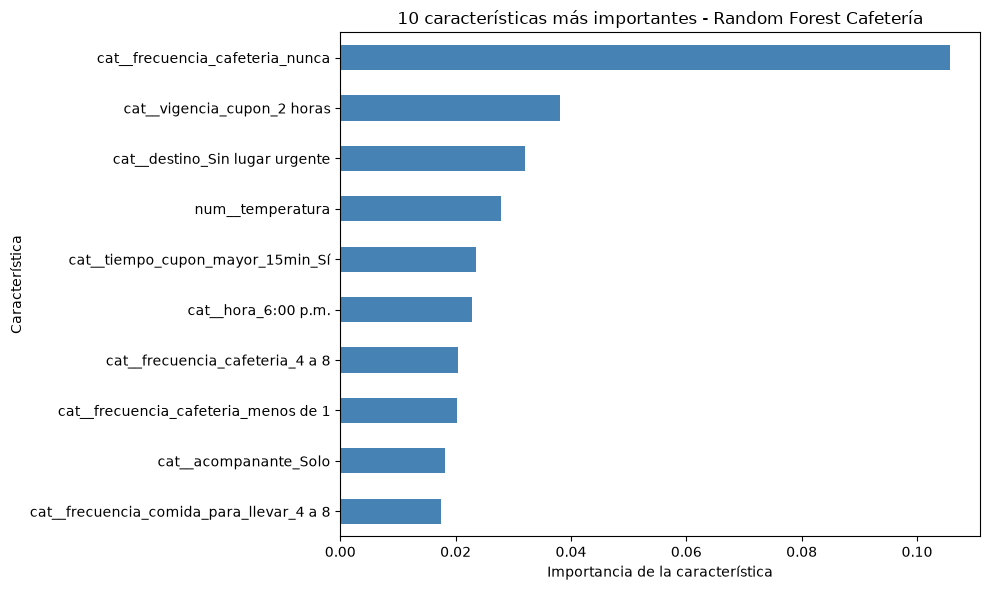

In [88]:
# Recuperar el mejor modelo de Cafetería
mejor_rf_caf = grid_rf_caf.best_estimator_

# Obtener el clasificador Random Forest
modelo_rf_caf = mejor_rf_caf.named_steps['modelo']

# Obtener nombres de las características transformadas
nombres_rf_caf = (
    mejor_rf_caf.named_steps['preprocesador']
    .get_feature_names_out()
)

# Calcular importancia de características
importancias_rf_caf = pd.Series(
    modelo_rf_caf.feature_importances_,
    index=nombres_rf_caf
)

# Seleccionar las diez más importantes
top_rf_caf = importancias_rf_caf.sort_values(
    ascending=False
).head(10)

print(top_rf_caf)

# Graficar
plt.figure(figsize=(10, 6))

top_rf_caf.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('10 características más importantes - Random Forest Cafetería')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 5.13. Análisis de importancia de características — Random Forest para Cafetería

El análisis de importancia de características del modelo Random Forest para Cafetería muestra que `frecuencia_cafeteria_nunca` presenta la mayor importancia individual, con un valor de 0,1056.

Le siguen `vigencia_cupon_2 horas` (0,0380), `destino_Sin lugar urgente` (0,0321), `temperatura` (0,0278), `tiempo_cupon_mayor_15min_Sí` (0,0235) y `hora_6:00 p.m.` (0,0228).

Estos resultados sugieren que los hábitos de consumo, la vigencia de la oferta y las condiciones del desplazamiento aportan información relevante para la clasificación.

Al comparar Random Forest con el árbol de decisión de Cafetería, se observa que ambos identifican la categoría correspondiente a quienes nunca visitan cafeterías como la característica individual de mayor importancia.

Sin embargo, en el árbol de decisión esta característica concentraba aproximadamente el 44,91 % de la importancia, mientras que en Random Forest representa el 10,56 %. Esto refleja una distribución más amplia de las importancias entre las características utilizadas por los árboles del ensamble.

Debe tenerse presente que las importancias corresponden a características transformadas mediante `OneHotEncoder`. Por tanto, las categorías de una misma variable original pueden aparecer de manera independiente. Además, estas importancias no representan efectos causales.

#### 5.14. Importancia de características — Random Forest para Restaurante(<20)

Se calcula la importancia de las características del mejor modelo Random Forest correspondiente a Restaurante(<20).

Para ello, se utiliza el atributo `feature_importances_` del clasificador y se recuperan los nombres de las características generadas durante el preprocesamiento.

Posteriormente, se representan gráficamente las diez características transformadas con mayor importancia.

Este análisis permitirá identificar los factores predictivos más relevantes para Restaurante(<20) y compararlos con los encontrados en Cafetería y en los modelos de árboles de decisión.

cat__vigencia_cupon_2 horas         0.052147
cat__clima_Soleado                  0.040216
cat__tiempo_cupon_mayor_25min_Sí    0.034585
cat__destino_Sin lugar urgente      0.031657
cat__hora_10:00 p.m.                0.025337
num__temperatura                    0.024463
cat__hora_6:00 p.m.                 0.021024
cat__tiempo_cupon_mayor_15min_Sí    0.020016
cat__frecuencia_bar_nunca           0.019688
cat__acompanante_Solo               0.018962
dtype: float64


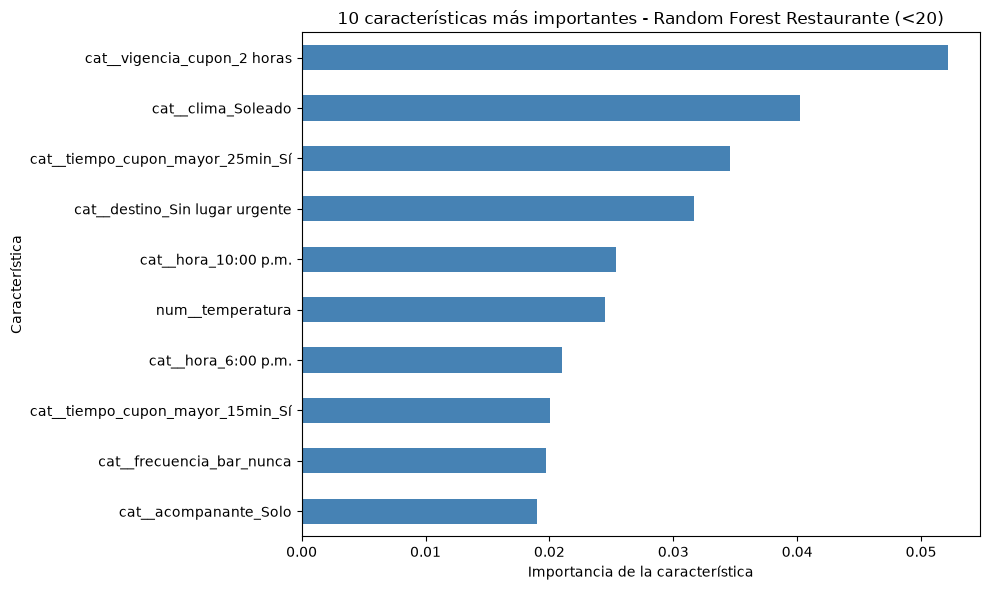

In [89]:
# Recuperar el mejor modelo de Restaurante (<20)
mejor_rf_res = grid_rf_res.best_estimator_

# Obtener el clasificador Random Forest
modelo_rf_res = mejor_rf_res.named_steps['modelo']

# Obtener los nombres de las características transformadas
nombres_rf_res = (
    mejor_rf_res.named_steps['preprocesador']
    .get_feature_names_out()
)

# Calcular importancia de características
importancias_rf_res = pd.Series(
    modelo_rf_res.feature_importances_,
    index=nombres_rf_res
)

# Seleccionar las diez características más importantes
top_rf_res = importancias_rf_res.sort_values(
    ascending=False
).head(10)

print(top_rf_res)

# Graficar
plt.figure(figsize=(10, 6))

top_rf_res.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('10 características más importantes - Random Forest Restaurante (<20)')
plt.xlabel('Importancia de la característica')
plt.ylabel('Característica')
plt.tight_layout()
plt.show()

#### 5.15. Análisis de importancia de características — Random Forest para Restaurante(<20)

El análisis de importancia de características del modelo Random Forest para Restaurante(<20) muestra que `vigencia_cupon_2 horas` presenta la mayor importancia individual, con un valor de 0,0521.

Le siguen `clima_Soleado` (0,0402), `tiempo_cupon_mayor_25min_Sí` (0,0346), `destino_Sin lugar urgente` (0,0317), `hora_10:00 p.m.` (0,0253) y `temperatura` (0,0245).

Estos resultados sugieren que la vigencia de la oferta, las condiciones del desplazamiento y el contexto del viaje proporcionan información relevante para predecir la aceptación de cupones de Restaurante(<20).

En comparación con Cafetería, donde la categoría correspondiente a quienes nunca visitan cafeterías presentó la mayor importancia individual, en Restaurante(<20) sobresalen características relacionadas con la oferta y las circunstancias del desplazamiento.

Asimismo, al comparar los resultados con el árbol de decisión de Restaurante(<20), se observa que ambos modelos consideran relevante el tiempo de desplazamiento, aunque distribuyen la importancia entre las características de manera diferente.

Debe tenerse en cuenta que las importancias corresponden a características transformadas mediante `OneHotEncoder`, por lo que una misma variable original puede estar representada por varias categorías. Estos resultados tampoco permiten establecer relaciones causales ni determinar por sí solos la dirección de la asociación con la aceptación del cupón.

### 6. Comparación de los modelos de clasificación

#### 6.1. Comparación de regresión logística, árbol de decisión y Random Forest

Se comparan los modelos de regresión logística, árbol de decisión y Random Forest desarrollados para Cafetería y Restaurante(<20).

Para garantizar una comparación consistente, se utilizan las predicciones sobre los mismos conjuntos de prueba, reservados previamente mediante una partición estratificada.

Se consideran accuracy, precision, recall y F1-score para la clase positiva, así como F1-score macro, con el propósito de evaluar el desempeño general y las diferencias entre clases.

La comparación permitirá identificar el modelo más adecuado para cada tipo de cupón, considerando tanto su desempeño predictivo como las limitaciones asociadas al desbalance de clases.

In [90]:
modelos_verificar = {
    'Logística Cafetería': grid_rl_caf,
    'Árbol Cafetería': grid_arbol_caf,
    'Random Forest Cafetería': grid_rf_caf,
    'Logística Restaurante': grid_rl_res,
    'Árbol Restaurante': grid_arbol_res,
    'Random Forest Restaurante': grid_rf_res
}

for nombre, modelo in modelos_verificar.items():
    columnas_modelo = modelo.best_estimator_.feature_names_in_

    print(nombre)
    print("Cantidad de variables:", len(columnas_modelo))
    print("Variables excluidas:",
          'cupon' not in columnas_modelo
          and 'tiempo_cupon_mayor_5min' not in columnas_modelo)
    print()

Logística Cafetería
Cantidad de variables: 22
Variables excluidas: True

Árbol Cafetería
Cantidad de variables: 22
Variables excluidas: True

Random Forest Cafetería
Cantidad de variables: 22
Variables excluidas: True

Logística Restaurante
Cantidad de variables: 22
Variables excluidas: True

Árbol Restaurante
Cantidad de variables: 22
Variables excluidas: True

Random Forest Restaurante
Cantidad de variables: 22
Variables excluidas: True



#### 6.2. Tabla comparativa de los modelos

Una vez verificado que los seis modelos utilizan las mismas 22 variables predictoras, se procede a comparar su desempeño sobre los conjuntos de prueba correspondientes.

Para cada tipo de cupón se consideran los siguientes indicadores:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** proporción de aceptaciones reales entre las predicciones de aceptación.
- **Recall:** proporción de aceptaciones correctamente identificadas.
- **F1-score:** media armónica entre precision y recall de la clase positiva.
- **F1-score macro:** promedio del F1-score de ambas clases, otorgándoles el mismo peso.

La comparación permitirá identificar los modelos con mejor desempeño y analizar las diferencias entre Cafetería y Restaurante(<20), especialmente frente al desbalance de clases.

In [91]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Modelos entrenados para Cafetería
modelos_caf = {
    'Regresión logística': grid_rl_caf,
    'Árbol de decisión': grid_arbol_caf,
    'Random Forest': grid_rf_caf
}

resultados_caf = []

for nombre, modelo in modelos_caf.items():
    predicciones = modelo.predict(X_test_caf)

    resultados_caf.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test_caf, predicciones),
        'Precision': precision_score(y_test_caf, predicciones),
        'Recall': recall_score(y_test_caf, predicciones),
        'F1-score': f1_score(y_test_caf, predicciones),
        'F1 macro': f1_score(
            y_test_caf, predicciones, average='macro'
        )
    })

tabla_caf = pd.DataFrame(resultados_caf)

print("COMPARACIÓN DE MODELOS - CAFETERÍA")
print(tabla_caf.round(4).to_string(index=False))


# Modelos entrenados para Restaurante (<20)
modelos_res = {
    'Regresión logística': grid_rl_res,
    'Árbol de decisión': grid_arbol_res,
    'Random Forest': grid_rf_res
}

resultados_res = []

for nombre, modelo in modelos_res.items():
    predicciones = modelo.predict(X_test_res)

    resultados_res.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test_res, predicciones),
        'Precision': precision_score(y_test_res, predicciones),
        'Recall': recall_score(y_test_res, predicciones),
        'F1-score': f1_score(y_test_res, predicciones),
        'F1 macro': f1_score(
            y_test_res, predicciones, average='macro'
        )
    })

tabla_res = pd.DataFrame(resultados_res)

print("\nCOMPARACIÓN DE MODELOS - RESTAURANTE (<20)")
print(tabla_res.round(4).to_string(index=False))

COMPARACIÓN DE MODELOS - CAFETERÍA
             Modelo  Accuracy  Precision  Recall  F1-score  F1 macro
Regresión logística    0.7005     0.6897  0.7261    0.7075    0.7003
  Árbol de decisión    0.7030     0.6930  0.7261    0.7092    0.7029
      Random Forest    0.7431     0.7239  0.7839    0.7527    0.7427

COMPARACIÓN DE MODELOS - RESTAURANTE (<20)
             Modelo  Accuracy  Precision  Recall  F1-score  F1 macro
Regresión logística    0.7734     0.7934  0.9186    0.8514    0.6871
  Árbol de decisión    0.7590     0.7627  0.9567    0.8488    0.6279
      Random Forest    0.7842     0.8013  0.9237    0.8582    0.7035


#### 6.3. Selección y justificación del mejor algoritmo

**Cafetería**

Los resultados muestran que Random Forest presenta el mejor desempeño entre los tres algoritmos evaluados.

Este modelo alcanzó un accuracy de 0,7431, precision de 0,7239, recall de 0,7839, F1-score de 0,7527 y F1 macro de 0,7427.

En comparación, la regresión logística obtuvo un F1-score de 0,7075 y el árbol de decisión de 0,7092.

Por tanto, Random Forest se selecciona como el mejor algoritmo para Cafetería, debido a que presenta los valores más altos en todas las métricas evaluadas y mantiene un desempeño relativamente equilibrado entre las clases de aceptación y rechazo.

**Restaurante(<20)**

Para Restaurante(<20), Random Forest también presenta el mejor desempeño general entre los algoritmos evaluados.

El modelo obtuvo un accuracy de 0,7842, precision de 0,8013, recall de 0,9237, F1-score de 0,8582 y F1 macro de 0,7035.

La regresión logística obtuvo un F1-score de 0,8514, mientras que el árbol de decisión alcanzó 0,8488.

Aunque el árbol de decisión presentó un recall superior para la clase positiva, Random Forest obtuvo los mayores valores de accuracy, precision, F1-score y F1 macro.

Por lo anterior, Random Forest se selecciona como el mejor algoritmo para Restaurante(<20), considerando el equilibrio general entre las métricas de evaluación.

No obstante, el modelo presenta limitaciones al identificar la clase minoritaria de rechazo, cuyo recall es aproximadamente 0,4479. Por esta razón, resulta importante considerar los efectos del balanceo de clases mediante SMOTE antes de establecer las conclusiones definitivas.

**Conclusión general**

Random Forest obtuvo el mejor desempeño predictivo en ambos tipos de cupón, de acuerdo con las métricas calculadas sobre los conjuntos de prueba.

Sin embargo, las diferencias en la distribución de clases entre Cafetería y Restaurante(<20) deben tenerse en cuenta al interpretar los resultados.

Asimismo, estos resultados corresponden a los conjuntos de prueba utilizados en el laboratorio y no garantizan el mismo desempeño sobre datos nuevos.

#### 6.4. Comparación gráfica del F1-score

Se representa gráficamente el F1-score obtenido por los tres algoritmos en los conjuntos de prueba de Cafetería y Restaurante(<20).

Esta visualización permite identificar las diferencias de desempeño entre regresión logística, árbol de decisión y Random Forest, y respalda la selección del mejor algoritmo para cada tipo de cupón.

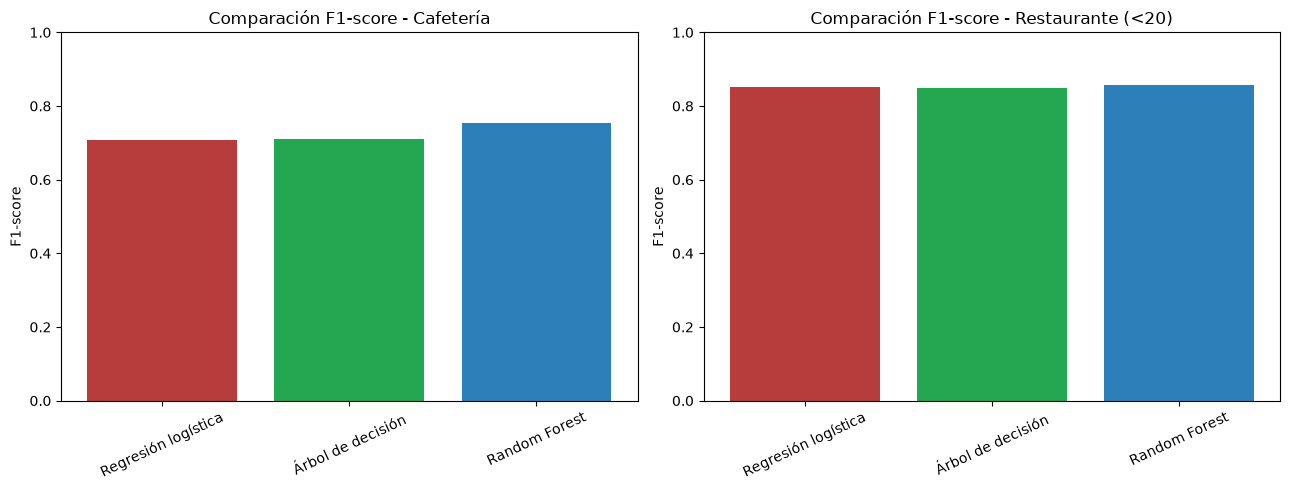

In [92]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Cafetería
axes[0].bar(
    tabla_caf['Modelo'],
    tabla_caf['F1-score'],
    color=['#B73C3C', '#23A751', '#2C7FB8']
)

axes[0].set_title('Comparación F1-score - Cafetería')
axes[0].set_ylabel('F1-score')
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis='x', rotation=25)

# Restaurante (<20)
axes[1].bar(
    tabla_res['Modelo'],
    tabla_res['F1-score'],
    color=['#B73C3C', '#23A751', '#2C7FB8']
)

axes[1].set_title('Comparación F1-score - Restaurante (<20)')
axes[1].set_ylabel('F1-score')
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

In [93]:
print("Variables utilizadas por el modelo con SMOTE:")
print(len(grid_rl_res_smote.best_estimator_.feature_names_in_))

print("\nVariables excluidas:")
columnas_smote = grid_rl_res_smote.best_estimator_.feature_names_in_

print("cupon:", 'cupon' not in columnas_smote)
print(
    "tiempo_cupon_mayor_5min:",
    'tiempo_cupon_mayor_5min' not in columnas_smote
)

Variables utilizadas por el modelo con SMOTE:
22

Variables excluidas:
cupon: True
tiempo_cupon_mayor_5min: True


#### Comparación definitiva del efecto de SMOTE — Restaurante(<20)

Para evaluar el efecto del balanceo de clases, se compara la regresión logística original con una regresión logística entrenada utilizando SMOTE.

Ambos modelos utilizan las mismas 22 variables predictoras y se evalúan sobre el mismo conjunto de prueba, que mantiene la distribución original de las clases.

Se consideran accuracy, precision, recall y F1-score de la clase positiva, así como F1-score macro y recall de la clase negativa.

Estas últimas métricas permiten determinar si el balanceo mejora la identificación de los conductores que rechazan el cupón, correspondientes a la clase minoritaria.

In [94]:
# Predicciones de los modelos
y_pred_sin_smote = grid_rl_res.predict(X_test_res)
y_pred_con_smote = grid_rl_res_smote.predict(X_test_res)

# Comparación de métricas
comparacion_smote = pd.DataFrame({
    'Modelo': ['Sin SMOTE', 'Con SMOTE'],
    'Accuracy': [
        accuracy_score(y_test_res, y_pred_sin_smote),
        accuracy_score(y_test_res, y_pred_con_smote)
    ],
    'Precision': [
        precision_score(y_test_res, y_pred_sin_smote),
        precision_score(y_test_res, y_pred_con_smote)
    ],
    'Recall (Sí)': [
        recall_score(y_test_res, y_pred_sin_smote),
        recall_score(y_test_res, y_pred_con_smote)
    ],
    'Recall (No)': [
        recall_score(y_test_res, y_pred_sin_smote, pos_label=0),
        recall_score(y_test_res, y_pred_con_smote, pos_label=0)
    ],
    'F1-score': [
        f1_score(y_test_res, y_pred_sin_smote),
        f1_score(y_test_res, y_pred_con_smote)
    ],
    'F1 macro': [
        f1_score(y_test_res, y_pred_sin_smote, average='macro'),
        f1_score(y_test_res, y_pred_con_smote, average='macro')
    ]
})

print(comparacion_smote.round(4).to_string(index=False))

   Modelo  Accuracy  Precision  Recall (Sí)  Recall (No)  F1-score  F1 macro
Sin SMOTE    0.7734     0.7934       0.9186       0.4233    0.8514    0.6871
Con SMOTE    0.7338     0.8551       0.7506       0.6933    0.7995    0.7019


#### Conclusiones del balanceo mediante SMOTE — Restaurante(<20)

La comparación de la regresión logística con y sin SMOTE evidencia cambios importantes en el desempeño de clasificación.

Sin SMOTE, el modelo obtuvo un accuracy de 0,7734, recall de aceptación de 0,9186, recall de rechazo de 0,4233, F1-score de aceptación de 0,8514 y F1 macro de 0,6871.

Después de aplicar SMOTE, el accuracy disminuyó a 0,7338, mientras que el recall de aceptación se redujo a 0,7506 y el F1-score de aceptación a 0,7995.

Sin embargo, el recall de rechazo aumentó de 0,4233 a 0,6933, una mejora de aproximadamente 27 puntos porcentuales. Adicionalmente, el F1 macro aumentó de 0,6871 a 0,7019.

Estos resultados muestran que SMOTE mejora la capacidad de identificar la clase minoritaria, correspondiente a los conductores que rechazan el cupón, aunque esta mejora implica una reducción en la capacidad de identificar aceptaciones.

En consecuencia, el balanceo puede resultar útil cuando se busca reducir la proporción de rechazos clasificados incorrectamente como aceptaciones. Por el contrario, si se prioriza el F1-score de aceptación, el modelo sin SMOTE presenta mejores resultados.

Es importante señalar que SMOTE se aplicó dentro del pipeline y durante la validación cruzada, evitando utilizar datos de prueba para generar observaciones sintéticas.

No obstante, como las variables categóricas fueron transformadas previamente mediante `OneHotEncoder`, SMOTE convencional puede generar observaciones sintéticas con valores intermedios entre las categorías codificadas. Por tanto, esta constituye una limitación metodológica del experimento.

En términos generales, el experimento evidencia que el balanceo de clases modifica el comportamiento del clasificador, pero no mejora simultáneamente todas las métricas de evaluación.

#### Visualización del efecto de SMOTE sobre el recall

Se representa gráficamente el recall de aceptación y de rechazo obtenido por los modelos de regresión logística con y sin SMOTE.

Esta comparación permite observar el efecto del balanceo sobre la capacidad del clasificador para identificar correctamente cada clase, especialmente los rechazos, que constituyen la clase minoritaria de Restaurante(<20).

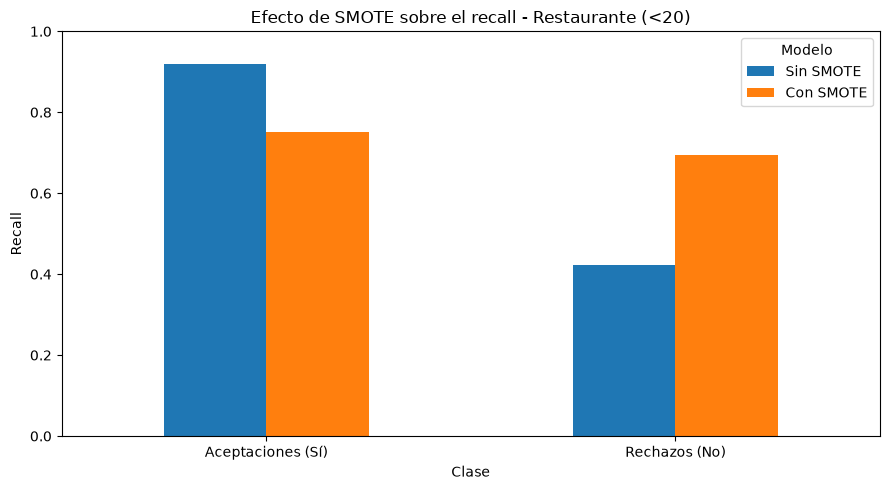

In [95]:
comparacion_recall = pd.DataFrame({
    'Sin SMOTE': [
        comparacion_smote.loc[0, 'Recall (Sí)'],
        comparacion_smote.loc[0, 'Recall (No)']
    ],
    'Con SMOTE': [
        comparacion_smote.loc[1, 'Recall (Sí)'],
        comparacion_smote.loc[1, 'Recall (No)']
    ]
}, index=['Aceptaciones (Sí)', 'Rechazos (No)'])

comparacion_recall.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Efecto de SMOTE sobre el recall - Restaurante (<20)')
plt.ylabel('Recall')
plt.xlabel('Clase')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()

## 7. Análisis de resultados

### 7.1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

Para identificar las características más relacionadas con la aceptación de cupones, se analizaron las importancias de variables obtenidas mediante Random Forest y árboles de decisión.

**Cafetería**

En el modelo Random Forest para Cafetería, la característica individual más importante fue `frecuencia_cafeteria_nunca`, con una importancia de 0,1056.

Otras características relevantes fueron la vigencia del cupón de dos horas (0,0380), el destino sin lugar urgente (0,0321), la temperatura (0,0278) y un tiempo de desplazamiento superior a 15 minutos (0,0235).

Estos resultados sugieren que los hábitos de consumo del conductor y las condiciones del desplazamiento aportan información relevante para predecir la aceptación de cupones de Cafetería.

Esta interpretación es consistente con el árbol de decisión, que también identificó la categoría correspondiente a quienes nunca visitan cafeterías como su característica principal.

**Restaurante(<20)**

En Random Forest para Restaurante(<20), la característica individual más importante fue la vigencia del cupón de dos horas (0,0521).

También destacaron el clima soleado (0,0402), el tiempo de desplazamiento superior a 25 minutos (0,0346), el destino sin lugar urgente (0,0317) y la hora de las 10:00 p. m. (0,0253).

Estos resultados sugieren que, para Restaurante(<20), las características relacionadas con la oferta y el contexto del viaje tienen una contribución relevante a las predicciones.

El árbol de decisión también identificó el tiempo de desplazamiento superior a 25 minutos como una característica importante.

**Comparación**

Los resultados indican que las características predictivas más destacadas varían según el tipo de cupón.

En Cafetería, los hábitos de consumo ocupan un lugar predominante, mientras que en Restaurante(<20) adquieren mayor relevancia la vigencia de la oferta y las condiciones del desplazamiento.

No obstante, estas conclusiones se basan en las importancias calculadas por los modelos y no permiten establecer relaciones causales ni determinar, por sí solas, si una característica aumenta o disminuye la probabilidad de aceptación.

Además, las importancias corresponden a las categorías generadas mediante `OneHotEncoder`, por lo que deben interpretarse considerando que una misma variable original puede estar representada por varias características transformadas.

### 7.2. ¿Existen variables que podrían ser redundantes o poco informativas?

Durante la exploración y preparación de los datos se identificaron características que aportaban poca información para la clasificación.

En primer lugar, la variable `cupon` presentaba un único valor dentro de cada subconjunto, debido a que los registros se separaron previamente en Cafetería y Restaurante(<20). Por tanto, no permitía distinguir entre conductores que aceptaban y rechazaban el cupón dentro de cada grupo.

De manera similar, `tiempo_cupon_mayor_5min` tomaba el valor "Sí" en todas las observaciones de ambos subconjuntos. Debido a su ausencia de variabilidad, tampoco proporcionaba información para diferenciar las clases.

Por estas razones, ambas variables fueron excluidas de los predictores y los modelos se entrenaron con 22 características en lugar de las 24 inicialmente consideradas.

Adicionalmente, se eliminó `vehiculo`, dado que aproximadamente el 99 % de sus registros presentaban valores faltantes, lo que limitaba su utilidad para el análisis.

Por otra parte, las características relacionadas con tiempos de desplazamiento superiores a 15 y 25 minutos podrían contener información parcialmente redundante, ya que describen condiciones relacionadas. Sin embargo, su posible redundancia no fue cuantificada, por lo que se conservaron ambas variables.

En conclusión, la preparación permitió eliminar características constantes o con una proporción muy elevada de información faltante, manteniendo aquellas que podían aportar información predictiva relevante.

Estas decisiones contribuyeron a simplificar los conjuntos de datos sin reducir el número de observaciones utilizadas para entrenar y evaluar los modelos.

### 7.3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? ¿A qué se atribuye esa diferencia?

Los resultados muestran diferencias en el desempeño y el comportamiento de los modelos desarrollados para Cafetería y Restaurante(<20).

En ambos subconjuntos, Random Forest obtuvo el mejor desempeño general entre los tres algoritmos evaluados.

Para Cafetería, Random Forest alcanzó un accuracy de 0,7431, F1-score de aceptación de 0,7527 y F1 macro de 0,7427.

Por su parte, para Restaurante(<20), Random Forest obtuvo un accuracy de 0,7842, F1-score de aceptación de 0,8582 y F1 macro de 0,7035.

Aunque Restaurante(<20) presenta un F1-score de aceptación superior, su F1 macro es menor, lo cual indica un desempeño menos equilibrado entre ambas clases.

Una posible explicación es la diferencia en la distribución de la variable objetivo. En Cafetería, las aceptaciones representan aproximadamente el 49,9 % de los registros, mientras que en Restaurante(<20) corresponden al 70,7 %.

Este desbalance puede favorecer la predicción de la clase mayoritaria y dificultar la identificación de los rechazos.

De hecho, el modelo Random Forest de Restaurante(<20) identificó correctamente el 92,37 % de las aceptaciones, pero solamente el 44,79 % de los rechazos.

En contraste, el modelo de Cafetería obtuvo un recall de 78,39 % para las aceptaciones y de 70,25 % para los rechazos, mostrando un desempeño más equilibrado.

Adicionalmente, las características predictivas más destacadas difieren entre ambos subconjuntos. En Cafetería sobresalen los hábitos de consumo, mientras que en Restaurante(<20) destacan la vigencia del cupón y las condiciones del desplazamiento.

En conclusión, las diferencias observadas podrían explicarse por el desbalance de clases, el tamaño de los subconjuntos y las distintas relaciones entre las características de entrada y la aceptación del cupón. Sin embargo, estas explicaciones son interpretaciones de los resultados y no constituyen pruebas de causalidad.

### 7.4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo?

La aplicación de SMOTE produjo resultados diferentes según la métrica de evaluación considerada.

Para analizar su efecto, se compararon dos modelos de regresión logística entrenados con las mismas 22 variables predictoras: uno sin balanceo y otro utilizando SMOTE.

El modelo sin SMOTE obtuvo un accuracy de 0,7734, recall de aceptación de 0,9186, recall de rechazo de 0,4233, F1-score de aceptación de 0,8514 y F1 macro de 0,6871.

Por su parte, el modelo con SMOTE obtuvo un accuracy de 0,7338, recall de aceptación de 0,7506, recall de rechazo de 0,6933, F1-score de aceptación de 0,7995 y F1 macro de 0,7019.

El cambio más relevante fue el incremento del recall de rechazo de 42,33 % a 69,33 %, equivalente a una mejora de aproximadamente 27 puntos porcentuales.

Esto significa que, después del balanceo, el modelo identificó correctamente una proporción considerablemente mayor de conductores que rechazaron el cupón.

Sin embargo, esta mejora estuvo acompañada de una disminución en el recall y el F1-score de las aceptaciones.

El F1 macro aumentó ligeramente, indicando un desempeño algo más equilibrado entre ambas clases.

Por tanto, no es posible afirmar que SMOTE mejoró todas las dimensiones del modelo. Su utilidad depende del objetivo de clasificación.

Si se busca identificar con mayor precisión los rechazos para evitar ofrecer cupones a conductores con baja probabilidad de aceptación, SMOTE puede resultar útil.

En cambio, si se prioriza el F1-score de la clase positiva para identificar aceptaciones, el modelo sin SMOTE presentó mejores resultados.

Finalmente, debe considerarse que SMOTE se aplicó después de la codificación de variables categóricas mediante `OneHotEncoder`, por lo que puede generar observaciones sintéticas con valores intermedios entre categorías. Esta constituye una limitación metodológica del experimento.

En conclusión, SMOTE permitió mejorar la identificación de la clase minoritaria, pero produjo un intercambio entre el desempeño de ambas clases.